In [1]:
import numpy as np
import picos as pc
import mosek
import qgeo as q
import numpy.linalg as la
from itertools import product
from picos import block
import qgeo as q
import math
import array
from itertools import permutations
import random
from random import randint
from picos import HermitianVariable, ComplexVariable
from scipy.stats import unitary_group
from scipy.stats import ortho_group
from matplotlib import pyplot as plt


def singlet(sh): #Singlet with Schmidt parameter sh
    state = np.sqrt(sh)*q.ket('01')-np.sqrt(1.-sh)*q.ket('10')
    state = q.dm(state)
    return state

def Werner(v,sh):
    wer = v*singlet(sh)+(1-v)*np.eye(4)/4
    return wer

def CHSH(state):
    X = np.array([[0.,1.],[1.,0.]])
    Z = np.diag([1.,-1.])
    A1 = X
    A2 = Z
    B1 = (X+Z)/np.sqrt(2)
    B2 = (X-Z)/np.sqrt(2)
    
    Op = np.kron(A1,B1)+np.kron(A1,B2)+np.kron(A2,B1)-np.kron(A2,B2)
    func = np.trace(state @ Op)
    
    return(func)


print(CHSH(singlet(0.5)))


    
    

-2.8284271247461903


In [4]:
import numpy as np
for n in range(7,40):
    num = 1/(2**np.floor(n/2)-1)
    print(num)

0.14285714285714285
0.06666666666666667
0.06666666666666667
0.03225806451612903
0.03225806451612903
0.015873015873015872
0.015873015873015872
0.007874015748031496
0.007874015748031496
0.00392156862745098
0.00392156862745098
0.0019569471624266144
0.0019569471624266144
0.0009775171065493646
0.0009775171065493646
0.0004885197850512946
0.0004885197850512946
0.0002442002442002442
0.0002442002442002442
0.00012208521548040532
0.00012208521548040532
6.103888176768602e-05
6.103888176768602e-05
3.051850947599719e-05
3.051850947599719e-05
1.5259021896696422e-05
1.5259021896696422e-05
7.629452739355006e-06
7.629452739355006e-06
3.8147118175957395e-06
3.8147118175957395e-06
1.907352270798246e-06
1.907352270798246e-06


In [2]:
lam = np.array([1.-p,p,0.,0.])
ent = []
for p in range(0,6):
    p /= 10
    A = np.diag(lam)
    negs = []
    for j in range(1000):
        O = ortho_group.rvs(4)
        OAO = O@A@O.T
        PT = q.ptranspose(OAO,[0],[2,2])
        evals, evects = la.eig(PT)
        neg = sum(abs(evals)-evals)/2
        negs.append(neg)
    ne = max(negs)
    ent.append(ne)



NameError: name 'p' is not defined

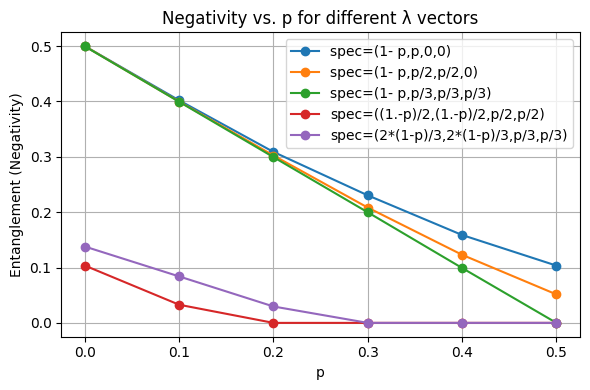

In [3]:

# Define different lambda vector schemes
lam_vectors = {
    'spec=(1- p,p,0,0)': lambda p: np.array([1. - p, p, 0., 0.]),
    'spec=(1- p,p/2,p/2,0)': lambda p: np.array([1. - p, p/2, p/2, 0.]),
    'spec=(1- p,p/3,p/3,p/3)': lambda p: np.array([1. - p, p/3, p/3, p/3]),
    'spec=((1.-p)/2,(1.-p)/2,p/2,p/2)': lambda p: np.array([(1.-p)/2,(1.-p)/2,p/2,p/2]),
    'spec=(2*(1-p)/3,2*(1-p)/3,p/3,p/3)': lambda p: np.array([2*(1-p)/3,2*(1-p)/3,p/3,p/3])
}

p_vals = [p / 10 for p in range(6)]

plt.figure(figsize=(6, 4))

for label, lam_func in lam_vectors.items():
    ent = []

    for p in p_vals:
        lam = lam_func(p)
        A = np.diag(lam)
        negs = []

        for j in range(1000):
            O = ortho_group.rvs(4)
            OAO = O @ A @ O.T
            PT = q.ptranspose(OAO, [0], [2, 2])  # Adapt if needed
            evals, _ = la.eig(PT)
            neg = sum(abs(evals) - evals) / 2
            negs.append(neg)

        ent.append(max(negs))

    plt.plot(p_vals, ent, marker='o', label=label)

plt.xlabel('p')
plt.ylabel('Entanglement (Negativity)')
plt.title('Negativity vs. p for different λ vectors')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [35]:
v_lb = 0.6595
v_ub = 1/np.sqrt(2) # If v > v_ub, then werner detected by CHSH

print(CHSH(Werner(v_ub,0.5)))


for i in range(10000):
    U = unitary_group.rvs(4)
    st = U@Werner(v_ub,0.1)@U.T.conj()
    val = CHSH(st)
    if abs(val) >= 2.:
        print(val)

-2.0


In [1]:
# mk bounds for ASN robustness

range(1, 10)


C:\Users\albert\AppData\Local\Temp\ipykernel_16896\3838077458.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("viridis")


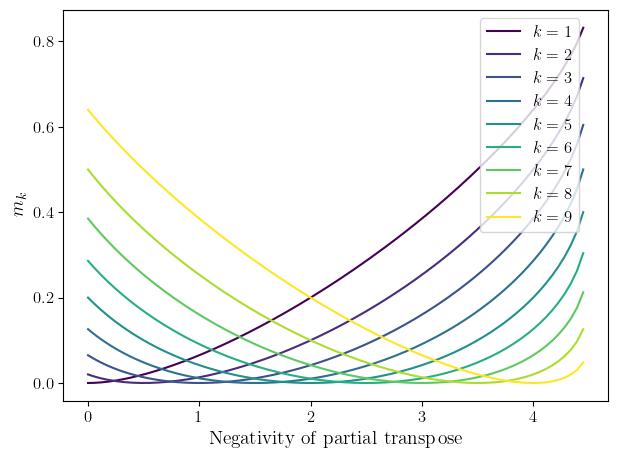

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import get_cmap

# -----------------------------
# LaTeX font configuration
# -----------------------------
rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# -----------------------------
# Parameters
# -----------------------------
N = 10
A = np.linspace(1, N, 500)
k_values = range(1, N)
print(k_values)

# -----------------------------
# Colormap
# -----------------------------
cmap = get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(k_values)))

# -----------------------------
# Plot
# -----------------------------
plt.figure()

for k, color in zip(k_values, colors):
    R = k + k**2 / (N - k)
    S = (2 * A * k) / (N - k)
    T = (A**2) / (N - k) - 1

    discriminant = S**2 - 4 * R * T
    mask = discriminant >= 0

    x = np.full_like(A, np.nan)
    x[mask] = (S[mask] + np.sqrt(discriminant[mask])) / (2 * R)

    #plt.plot(A, 1 - x, color=color, label=rf"$k={k}$")
    plt.plot((A**2-1)/2, 1 - k*x**2, color=color, label=rf"$k={k}$")

# -----------------------------
# Formatting
# -----------------------------
plt.xlabel(r"Negativity of partial transpose")
plt.ylabel(r"$m_k$")
#plt.title(r"$x$ vs $A$ for different $k$")
plt.legend(bbox_to_anchor=(0.75, 1), loc="upper left")
plt.grid(False)
plt.tight_layout()

plt.show()


C:\Users\albert\AppData\Local\Temp\ipykernel_16896\3368454591.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("viridis")
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


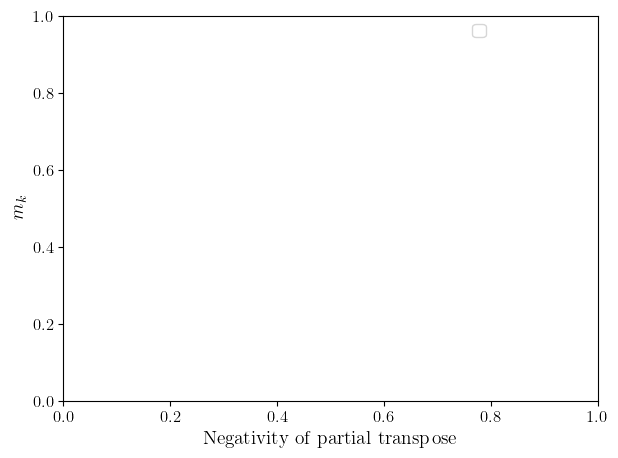

In [43]:
# Mask impossible mk:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import get_cmap

# -----------------------------
# LaTeX font configuration
# -----------------------------
rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# -----------------------------
# Parameters
# -----------------------------
N = 10
A = np.linspace(1, N, 500)
k_values = list(range(1, N))

# -----------------------------
# Colormap
# -----------------------------
cmap = get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(k_values)))

# -----------------------------
# Precompute x_k(A) and y_k(A)
# -----------------------------
x_dict = {}
y_dict = {}

for k in k_values:
    R = k + k**2 / (N - k)
    S = (2 * A * k) / (N - k)
    T = (A**2) / (N - k) - 1

    discriminant = S**2 - 4 * R * T
    mask = discriminant >= 0

    x = np.full_like(A, np.nan)
    x[mask] = (S[mask] + np.sqrt(discriminant[mask])) / (2 * R)

    x_dict[k] = x
    y_dict[k] = 1 - k * x**2

# -----------------------------
# Plot with dominance masking
# -----------------------------
plt.figure()

for k, color in zip(k_values, colors):
    yk = y_dict[k]

    # -----------------------------
    # MASK CONDITION
    # -----------------------------
    # Start assuming y_k is dominant everywhere
    dominance_mask = np.ones_like(A, dtype=bool)

    # Compare against all higher k'
    for kp in k_values:
        if kp > k:
            dominance_mask &= yk > y_dict[kp]

    # Mask where dominance condition holds
    yk_masked = np.copy(yk)
    yk_masked[dominance_mask] = np.nan

    plt.plot((A**2 - 1) / 2, yk_masked, color=color, label=rf"$k={k}$")

# -----------------------------
# Formatting
# -----------------------------
plt.xlabel(r"Negativity of partial transpose")
plt.ylabel(r"$m_k$")
plt.legend(bbox_to_anchor=(0.75, 1), loc="upper left")
plt.grid(False)
plt.tight_layout()
plt.show()


C:\Users\albert\AppData\Local\Temp\ipykernel_928\1237695190.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("viridis")
C:\Users\albert\AppData\Local\Temp\ipykernel_928\1237695190.py:39: RuntimeWarning: invalid value encountered in sqrt
  x = (A*k - np.sqrt(k*(N-k)*(N - A**2))) / (k*N)


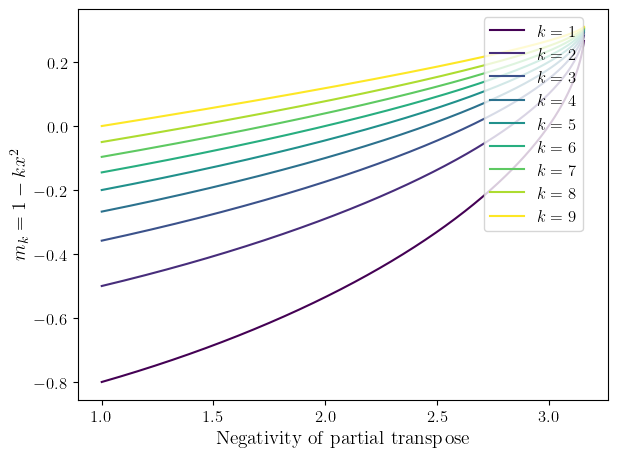

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import get_cmap

# -----------------------------
# LaTeX font configuration
# -----------------------------
rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# -----------------------------
# Parameters
# -----------------------------
N = 10
A = np.linspace(1, np.sqrt(N), 500)  # domain where sqrt is real
k_values = range(1, N)

# -----------------------------
# Colormap
# -----------------------------
cmap = get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(k_values)))

# -----------------------------
# Plot
# -----------------------------
plt.figure()

for k, color in zip(k_values, colors):
    x = (A*k - np.sqrt(k*(N-k)*(N - A**2))) / (k*N) # Careful this is with minius sign! Convex but negative
    #plt.plot((A**2 - 1)/2, 1 - k*x**2, color=color, label=rf"$k={k}$")
    plt.plot(A, x, color=color, label=rf"$k={k}$")

# -----------------------------
# Formatting
# -----------------------------
plt.xlabel(r"Negativity of partial transpose")
plt.ylabel(r"$m_k = 1 - kx^2$")
plt.legend(bbox_to_anchor=(0.75, 1), loc="upper left")
plt.grid(False)
plt.tight_layout()

plt.show()


C:\Users\albert\AppData\Local\Temp\ipykernel_37744\3320506676.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("viridis")


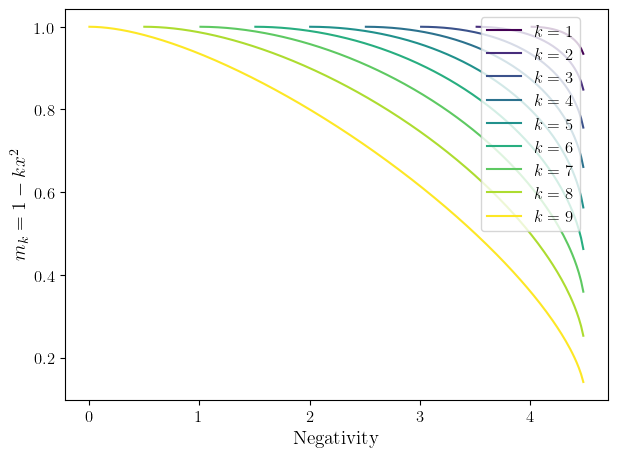

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import get_cmap

# -----------------------------
# LaTeX font configuration
# -----------------------------
rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# -----------------------------
# Parameters
# -----------------------------
N = 10
A = np.linspace(-np.sqrt(N), np.sqrt(N), 1000)  # full domain
k_values = range(1, N)

# -----------------------------
# Colormap
# -----------------------------
cmap = get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(k_values)))

# -----------------------------
# Plot
# -----------------------------
plt.figure()

for k, color in zip(k_values, colors):
    disc = k*(N-k)*(N - A**2)
    x = np.full_like(A, np.nan)

    valid = disc >= 0
    x[valid] = (A[valid]*k - np.sqrt(disc[valid])) / (k*N)

    # KEEP ONLY x >= 0
    x[x < 0] = np.nan

    #plt.plot(A, x, color=color, label=rf"$k={k}$")
    plt.plot((A**2 - 1)/2, 1 - k*x**2, color=color, label=rf"$k={k}$")

# -----------------------------
# Formatting
# -----------------------------
plt.xlabel(r"Negativity")
#plt.ylabel(r"$x$")
plt.ylabel(r"$m_k = 1 - kx^2$")
plt.legend(bbox_to_anchor=(0.75, 1), loc="upper left")
plt.grid(False)
plt.tight_layout()

plt.show()


C:\Users\albert\AppData\Local\Temp\ipykernel_3856\2428373360.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("viridis")


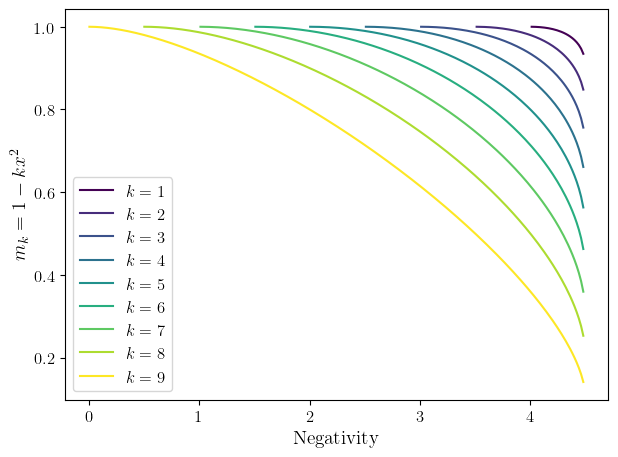

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import get_cmap

# -----------------------------
# LaTeX font configuration
# -----------------------------
rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# -----------------------------
# Parameters
# -----------------------------
N = 10
A = np.linspace(-np.sqrt(N), np.sqrt(N), 1000)  # full domain
k_values = range(1, N)

# -----------------------------
# Colormap
# -----------------------------
cmap = get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(k_values)))

# -----------------------------
# Plot
# -----------------------------
plt.figure()

for k, color in zip(k_values, colors):
    disc = k*(N-k)*(N - A**2)
    x = np.full_like(A, np.nan)

    valid = disc >= 0
    x[valid] = (A[valid]*k - np.sqrt(disc[valid])) / (k*N)

    # Keep only x >= 0
    x[x < 0] = np.nan

    #plt.plot(A, x, color=color, label=rf"$k={k}$")
    plt.plot((A**2 - 1)/2, 1 - k*x**2, color=color, label=rf"$k={k}$")

# -----------------------------
# Formatting
# -----------------------------
plt.xlabel(r"Negativity")
plt.ylabel(r"$m_k = 1 - kx^2$")
plt.legend(loc="lower left")   # ← legend inside, bottom-left
plt.grid(False)
plt.tight_layout()

plt.show()


C:\Users\albert\AppData\Local\Temp\ipykernel_16896\12346200.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("viridis")


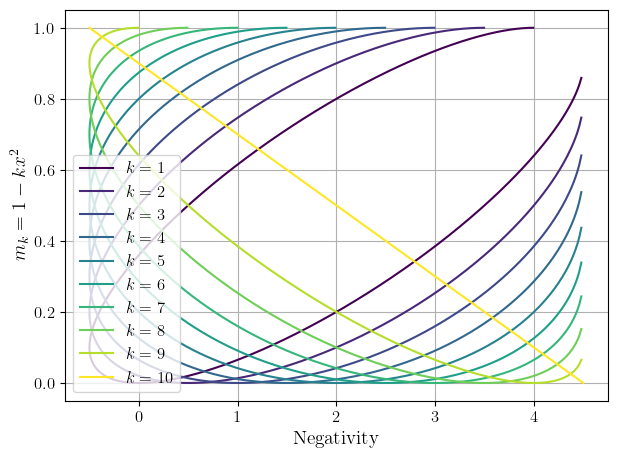

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import get_cmap

# -----------------------------
# LaTeX font configuration
# -----------------------------
rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# -----------------------------
# Parameters
# -----------------------------
N = 10
A = np.linspace(-np.sqrt(N), np.sqrt(N), 1000)  # full domain
k_values = range(1, N+1)

# -----------------------------
# Colormap
# -----------------------------
cmap = get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(k_values)))

# -----------------------------
# Plot
# -----------------------------
plt.figure()

for k, color in zip(k_values, colors):
    disc = k*(N-k)*(N - A**2)
    x = np.full_like(A, np.nan)

    valid = disc >= 0
    x[valid] = (A[valid]*k + np.sqrt(disc[valid])) / (k*N)

    # Keep only x >= 0
    x[x < 0] = np.nan

    #plt.plot(A, x, color=color, label=rf"$k={k}$")
    plt.plot((A**2 - 1)/2, 1 - k*x**2, color=color, label=rf"$k={k}$")

# -----------------------------
# Formatting
# -----------------------------
plt.xlabel(r"Negativity")
plt.ylabel(r"$m_k = 1 - kx^2$")
plt.legend(loc="lower left")   # ← legend inside, bottom-left
plt.grid(True)
plt.tight_layout()

plt.show()


C:\Users\albert\AppData\Local\Temp\ipykernel_16896\760251803.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("viridis")
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


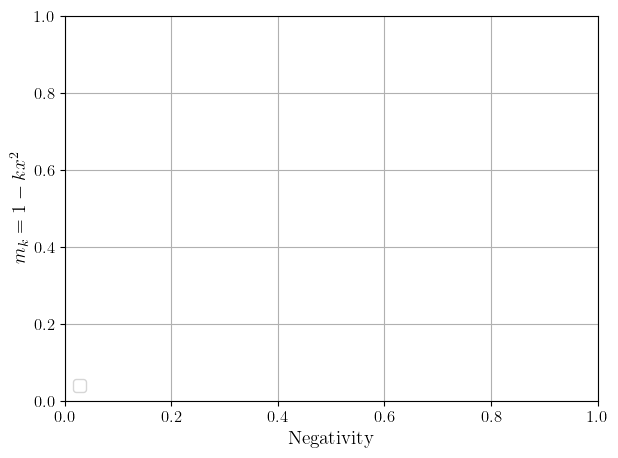

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import get_cmap

# -----------------------------
# LaTeX font configuration
# -----------------------------
rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# -----------------------------
# Parameters
# -----------------------------
N = 10
A = np.linspace(-np.sqrt(N), np.sqrt(N), 1000)  # full domain
k_values = range(1, N)

# -----------------------------
# Colormap
# -----------------------------
cmap = get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(k_values)))

# -----------------------------
# Plot
# -----------------------------
plt.figure()

for k, color in zip(k_values, colors):
    disc = k*(N-k)*(N - A**2)
    x = np.full_like(A, np.nan)

    valid = disc >= 0
    x[valid] = (A[valid]*k - np.sqrt(disc[valid])) / (k*N)

    # Keep only x >= 0
    x[x < 0] = np.nan

    # ---- SMALL MODIFICATION: keep only x >= 1/N ----
    #x[x < 1/np.sqrt(N)] = np.nan

    #plt.plot((A**2 - 1)/2, 1 - k*x**2,
    #         color=color, label=rf"$k={k}$")

# -----------------------------
# Formatting
# -----------------------------
plt.xlabel(r"Negativity")
plt.ylabel(r"$m_k = 1 - kx^2$")
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()

plt.show()


C:\Users\albert\AppData\Local\Temp\ipykernel_16896\1896826218.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("viridis")


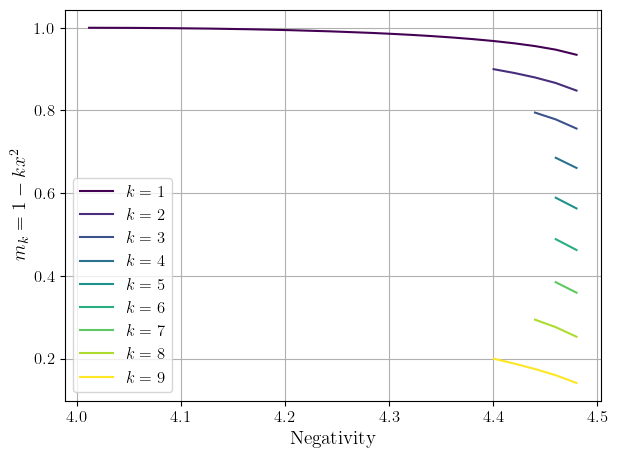

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.cm import get_cmap

# -----------------------------
# LaTeX font configuration
# -----------------------------
rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 14,
    "font.size": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# -----------------------------
# Parameters
# -----------------------------
N = 10
A = np.linspace(-np.sqrt(N), np.sqrt(N), 1000)  # full domain
k_values = range(1, N)

# -----------------------------
# Colormap
# -----------------------------
cmap = get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(k_values)))

# -----------------------------
# Precompute x and m_k for all k
# -----------------------------
x_vals = np.full((len(k_values), len(A)), np.nan)
m_vals = np.full((len(k_values), len(A)), np.nan)

for idx, k in enumerate(k_values):
    disc = k*(N-k)*(N - A**2)
    valid = disc >= 0
    x = np.full_like(A, np.nan)
    x[valid] = (A[valid]*k - np.sqrt(disc[valid])) / (k*N)
    x[x < 0] = np.nan
    x_vals[idx] = x
    m_vals[idx] = 1 - k * x**2

# -----------------------------
# Mask unphysical regions
# -----------------------------
for idx, k in enumerate(k_values):
    if k == 1:
        continue
    # maximum allowed value for m_k: smallest value of previous line
    m_max = 1 - (k-1)/N
    mask = m_vals[idx] > m_max
    m_vals[idx][mask] = np.nan

# -----------------------------
# Plot
# -----------------------------
plt.figure()
for idx, k in enumerate(k_values):
    plt.plot((A**2 - 1)/2, m_vals[idx], color=colors[idx], label=rf"$k={k}$")

# -----------------------------
# Formatting
# -----------------------------
plt.xlabel(r"Negativity")
plt.ylabel(r"$m_k = 1 - k x^2$")
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.show()


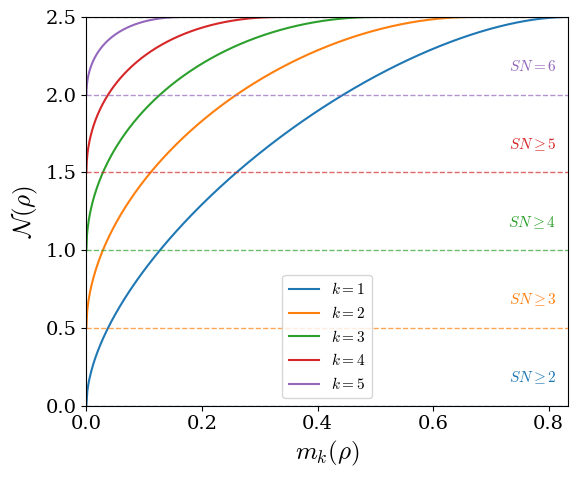

In [52]:
import numpy as np
import matplotlib.pyplot as plt

# Configure matplotlib to use a LaTeX-like font (Computer Modern)
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm", 
    "font.size": 14
})

def n_max(t, k, d):
    """Computes the value of N_max(t)"""
    x = np.sqrt((1 - t) / k)
    y = np.sqrt(t / (d - k))
    return ((k * x + (d - k) * y)**2 - 1) / 2

def plot_function():
    size = 18
    # Parameters
    d = 6
    k_values = [1, 2, 3, 4, 5, 6, 7]
    y_limit = (d - 1) / 2 # 3.5
    
    plt.figure(figsize=(6, 5))
    
    max_t = 0
    # Dictionary to map k value to its plotted color
    k_to_color = {}

    # Step 1: Plot curves and store colors indexed by k
    for k in k_values:
        t_max_val = 1 - k / d
        if t_max_val > 0:
            t = np.linspace(0, t_max_val, 500)
            y = n_max(t, k, d)
            y = np.clip(y, None, y_limit)
            max_t = max(max_t, t_max_val)
            
            line, = plt.plot(t, y, label=rf'$k = {k}$')
            k_to_color[k] = line.get_color()

    # Step 2: Add dashed lines. 
    # The intercept at t=0 is (k-1)/2. 
    # Therefore, a line at height 'val' corresponds to k = 2*val + 1.
    intervals = np.arange(0.0, y_limit + 0.5, 0.5)
    
    for val in intervals:
        # Calculate which k starts at this height
        target_k = int(round(2 * val + 1))
        
        # Get color of that specific k curve
        current_color = k_to_color.get(target_k, 'gray')
        
        plt.axhline(y=val, color=current_color, linestyle='--', linewidth=1.0, alpha=0.7)
        
        sn_val = int(2 * val)
        label_text = rf'$SN \geq {sn_val+2}$'
        if sn_val == 4:
            label_text = rf'$SN = {sn_val+2}$'
        
        # Position: right-hand side, slightly below the line
        
        if val < y_limit:
            plt.text(max_t-0.02, val + 0.15, label_text, 
                 color=current_color, fontsize=11, horizontalalignment='right')

    # Formatting the plot
    plt.xlabel(r'$m_k(\rho)$', fontsize=size)
    plt.ylabel(r'$\mathcal{N}(\rho)$', fontsize=size)
    
    plt.grid(False)
    plt.legend(loc='lower center', frameon=True, fontsize=11, borderaxespad=0.5)
    
    # Exact limits
    plt.xlim(0, max_t)
    plt.ylim(0, y_limit) 
    
    # Ensure axes start at 0
    plt.gca().spines['left'].set_position(('data', 0))
    plt.gca().spines['bottom'].set_position(('data', 0))
    
    plt.tight_layout()
    plt.savefig('n_max_intercept_colors.png', dpi=300)
    plt.show()

if __name__ == "__main__":
    plot_function()

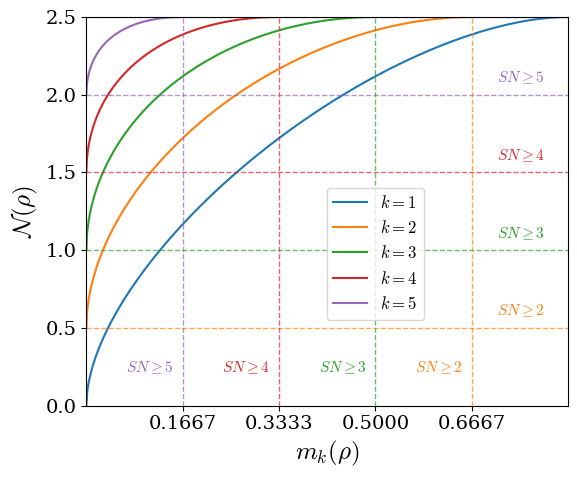

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# Configure matplotlib to use a LaTeX-like font (Computer Modern)
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 14
})

def n_max(t, k, d):
    """Computes the value of N_max(t)"""
    x = np.sqrt((1 - t) / k)
    y = np.sqrt(t / (d - k))
    return ((k * x + (d - k) * y)**2 - 1) / 2

def plot_function():
    size = 18
    
    # Parameters
    d = 6
    k_values = [1, 2, 3, 4, 5, 6, 7]
    y_limit = (d - 1) / 2
    
    plt.figure(figsize=(6, 5))
    
    max_t = 0
    k_to_color = {}

    # ---- Plot curves ----
    for k in k_values:
        t_max_val = 1 - k / d
        if t_max_val > 0:
            t = np.linspace(0, t_max_val, 500)
            y = n_max(t, k, d)
            y = np.clip(y, None, y_limit)
            max_t = max(max_t, t_max_val)

            line, = plt.plot(t, y, label=rf'$k = {k}$')
            k_to_color[k] = line.get_color()

    # ---- Horizontal dashed lines ----
    intervals = np.arange(0.5, y_limit + 0.5, 0.5)

    for val in intervals:
        target_k = int(round(2 * val + 1))
        current_color = k_to_color.get(target_k, 'gray')

        plt.axhline(y=val,
                    color=current_color,
                    linestyle='--',
                    linewidth=1.0,
                    alpha=0.7)

        sn_val = int(2 * val)
        label_text = rf'$SN \geq {sn_val+1}$'

        if val < y_limit:
            plt.text(max_t - 0.04,
                     val + 0.08,
                     label_text,
                     color=current_color,
                     fontsize=11,
                     horizontalalignment='right')

    # ---- EXACTLY 4 Vertical dashed lines (equally spaced) ----
    num_vertical = 4
    vertical_positions = np.linspace(0, max_t, num_vertical + 2)[1:-1]

    # Collect original colors and labels
    vertical_colors = []
    vertical_labels = []

    for i in range(num_vertical):
        corresponding_val = intervals[i]
        target_k = int(round(2 * corresponding_val + 1))
        color = k_to_color.get(target_k, 'gray')

        sn_val = int(2 * corresponding_val)
        label_text = rf'$SN \geq {7 - sn_val - 1}$'

        vertical_colors.append(color)
        vertical_labels.append(label_text)

    # Reverse color order
    reversed_colors = vertical_colors[::-1]

    for i, val in enumerate(vertical_positions):

        current_color = reversed_colors[i]

        plt.axvline(x=val,
                    color=current_color,
                    linestyle='--',
                    linewidth=1.0,
                    alpha=0.7)

        plt.text(val - 0.015,
                 0.3,
                 vertical_labels[i],
                 color=current_color,
                 fontsize=11,
                 horizontalalignment='right',
                 verticalalignment='top')

    # ---- Set x-ticks ONLY at vertical dashed lines ----
    plt.xticks(vertical_positions)

    # ---- Formatting ----
    plt.xlabel(r'$m_k(\rho)$', fontsize=size)
    plt.ylabel(r'$\mathcal{N}(\rho)$', fontsize=size)

    plt.grid(False)
    plt.legend(loc='lower center',
               bbox_to_anchor=(0.6, 0.2),
               frameon=True,
               fontsize=12,
               borderaxespad=0.5)

    plt.xlim(0, max_t)
    plt.ylim(0, y_limit)

    plt.gca().spines['left'].set_position(('data', 0))
    plt.gca().spines['bottom'].set_position(('data', 0))

    plt.tight_layout()
    plt.savefig('n_max_intercept_colors.png', dpi=300)
    plt.show()

if __name__ == "__main__":
    plot_function()


In [16]:
# Finding almost ames

import itertools
import numpy as np
import picos as pic

# --------------------------------------------------
# Parameters
# --------------------------------------------------

k = 2                 # number of qubits per A or B
d = 2**k
D = d**4

# --------------------------------------------------
# Indexing helpers
# --------------------------------------------------

def idx(a1, b1, a2, b2):
    return ((a1*d + b1)*d + a2)*d + b2

def unravel(i):
    b2 = i % d
    i //= d
    a2 = i % d
    i //= d
    b1 = i % d
    a1 = i // d
    return a1, b1, a2, b2

# --------------------------------------------------
# Problem
# --------------------------------------------------

P = pic.Problem()

# diagonal variables
x = pic.RealVariable("x", D)

# positivity and trace
P.add_constraint(x >= 0)
P.add_constraint(pic.sum(x) == 1)

# --------------------------------------------------
# Objective: tr(VX)
# --------------------------------------------------

objective_indices = [
    idx(a, b, a, b)
    for a in range(d)
    for b in range(d)
]

P.set_objective(
    "max",
    pic.sum(x[i] for i in objective_indices)
)

# --------------------------------------------------
# Swap invariance: x[a1 b1 a2 b2] = x[a2 b2 a1 b1]
# --------------------------------------------------

for a1, b1, a2, b2 in itertools.product(range(d), repeat=4):
    i = idx(a1, b1, a2, b2)
    j = idx(a2, b2, a1, b1)
    if i < j:
        P.add_constraint(x[i] == x[j])

# --------------------------------------------------
# Equal marginals
# --------------------------------------------------

for a1, b1 in itertools.product(range(d), repeat=2):
    lhs = pic.sum(
        x[idx(a1, b1, a2, b2)]
        for a2, b2 in itertools.product(range(d), repeat=2)
    )
    rhs = pic.sum(
        x[idx(a2, b2, a1, b1)]
        for a2, b2 in itertools.product(range(d), repeat=2)
    )
    P.add_constraint(lhs == rhs)

# --------------------------------------------------
# PPT constraint on (VX)^{T_{A2B2}}
# --------------------------------------------------

M = pic.HermitianVariable("M", D)

for i in range(D):
    a1, b1, a2, b2 = unravel(i)
    j = idx(a2, b2, a1, b1)
    M[i, j] = x[j]

# partial transpose on A2B2
for i, j in itertools.product(range(D), repeat=2):
    a1, b1, a2, b2 = unravel(i)
    c1, d1, c2, d2 = unravel(j)

    if (a2, b2, c2, d2) != (c2, d2, a2, b2):
        M[i, j] = M[
            idx(a1, b1, c2, d2),
            idx(c1, d1, a2, b2)
        ]

P.add_constraint(M >> 0)

# --------------------------------------------------
# APPT constraint on X_{A1B1}
# --------------------------------------------------

# Reduced diagonal
rho_diag = [
    pic.sum(
        x[idx(a1, b1, a2, b2)]
        for a2, b2 in itertools.product(range(d), repeat=2)
    )
    for a1, b1 in itertools.product(range(d), repeat=2)
]

rho = pic.diag(rho_diag)

# all bipartitions of 2k qubits
for mask in range(1, 2**(2*k - 1)):
    rho_pt = pic.partial_transpose(
        rho,
        dims=[2]*(2*k),
        subsys=[
            i for i in range(2*k)
            if (mask >> i) & 1
        ]
    )
    P.add_constraint(rho_pt >> 0)

# --------------------------------------------------
# Solve
# --------------------------------------------------

P.solve(solver="cvxopt", verbose=True)

print("Optimal value:", P.value)


TypeError: 'HermitianVariable' object does not support item assignment

In [25]:
import itertools
import picos as pic

# ==================================================
# Parameters
# ==================================================

k = 2                  # number of qubits per A or B
d = 2**k
D = d**4
dAB = d**2

# ==================================================
# Indexing
# ==================================================

def idx(a1, b1, a2, b2):
    return ((a1*d + b1)*d + a2)*d + b2

def idx_AB(a, b):
    return a*d + b

# ==================================================
# Problem
# ==================================================

P = pic.Problem()

# diagonal variables x >= 0
x = pic.RealVariable("x", D, lower=0)

# trace = 1
P.add_constraint(pic.sum(x) == 1)

# ==================================================
# Objective: tr(VX)
# ==================================================

P.set_objective(
    "max",
    pic.sum(x[idx(a, b, a, b)] for a in range(d) for b in range(d))
)

# ==================================================
# Swap invariance
# ==================================================

for a1, b1, a2, b2 in itertools.product(range(d), repeat=4):
    i = idx(a1, b1, a2, b2)
    j = idx(a2, b2, a1, b1)
    if i < j:
        P.add_constraint(x[i] == x[j])

# ==================================================
# Equal marginals
# ==================================================

for a1, b1 in itertools.product(range(d), repeat=2):
    lhs = pic.sum(
        x[idx(a1, b1, a2, b2)]
        for a2, b2 in itertools.product(range(d), repeat=2)
    )
    rhs = pic.sum(
        x[idx(a2, b2, a1, b1)]
        for a2, b2 in itertools.product(range(d), repeat=2)
    )
    P.add_constraint(lhs == rhs)

# ==================================================
# APPT constraint on X_{A1B1}
# ==================================================

rho = pic.HermitianVariable("rho", (dAB, dAB))

# diagonal entries
for a1, b1 in itertools.product(range(d), repeat=2):
    i = idx_AB(a1, b1)
    P.add_constraint(
        rho[i, i]
        ==
        pic.sum(
            x[idx(a1, b1, a2, b2)]
            for a2, b2 in itertools.product(range(d), repeat=2)
        )
    )

# off-diagonal entries = 0
for i in range(dAB):
    for j in range(dAB):
        if i != j:
            P.add_constraint(rho[i, j] == 0)

# ==================================================
# PPT on A1|B1
# ==================================================

dims = [(d, d), (d, d)]

P.add_constraint(pic.partial_transpose(rho, [0], dims) >> 0)
P.add_constraint(pic.partial_transpose(rho, [1], dims) >> 0)

# ==================================================
# Solve
# ==================================================

P.solve(solver="cvxopt", verbose=True)

print("\nStatus:", P.status)
print("Optimal value:", P.value)


           PICOS 2.4.17            


C:\Users\albert\AppData\Local\Temp\ipykernel_31564\2173477362.py:106: DeprecationWarning: Option 'verbose' is deprecated, use 'verbosity'.
  P.solve(solver="cvxopt", verbose=True)


Problem type: Complex Semidefinite Program.
Searching a solution strategy for CVXOPT.
Solution strategy:
  1. ExtraOptions
  2. ComplexAffineToRealReformulation
  3. ComplexLMIToRealReformulation
  4. CVXOPTSolver
Applying ExtraOptions.
Applying ComplexAffineToRealReformulation.
Applying ComplexLMIToRealReformulation.
Building a CVXOPT problem instance.
Starting solution search.
-----------------------------------
 Python Convex Optimization Solver 
    via internal CONELP solver     
-----------------------------------
     pcost       dcost       gap    pres   dres   k/t
 0: -6.2500e-02 -6.2500e-02  1e+01  1e-09  1e+01  1e+00
 1: -2.1434e-01 -3.1325e-01  1e+00  1e-10  1e+00  1e-02
 2: -9.9214e-01 -1.0425e+00  6e-01  6e-11  6e-01  3e-03
 3: -9.9919e-01 -9.9977e-01  7e-03  6e-13  7e-03  4e-05
 4: -9.9999e-01 -1.0000e+00  7e-05  7e-15  7e-05  4e-07
 5: -1.0000e+00 -1.0000e+00  7e-07  2e-15  7e-07  4e-09
 6: -1.0000e+00 -1.0000e+00  7e-09  6e-15  7e-09  4e-11
Optimal solution found.
----

In [18]:
pip install picos cvxopt


[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import itertools
import picos as pic
import numpy as np

# ==================================================
# Parameters
# ==================================================

k = 4                  # qubits per A or B
d = 2**k
D = d**4
dAB = d**2

# ==================================================
# Indexing
# ==================================================

def idx(a1, b1, a2, b2):
    return ((a1*d + b1)*d + a2)*d + b2

def idx_AB(a, b):
    return a*d + b

# ==================================================
# Problem
# ==================================================

P = pic.Problem()

# Diagonal variables x >= 0
x = pic.RealVariable("x", D, lower=0)

# Trace = 1
P.add_constraint(pic.sum(x) == 1)

# ==================================================
# Objective: tr(VX)
# ==================================================

P.set_objective(
    "max",
    pic.sum(x[idx(a, b, a, b)] for a in range(d) for b in range(d))
)

# ==================================================
# Swap invariance
# ==================================================

for a1, b1, a2, b2 in itertools.product(range(d), repeat=4):
    i = idx(a1, b1, a2, b2)
    j = idx(a2, b2, a1, b1)
    if i < j:
        P.add_constraint(x[i] == x[j])

# ==================================================
# Equal marginals
# ==================================================

for a1, b1 in itertools.product(range(d), repeat=2):
    lhs = pic.sum(
        x[idx(a1, b1, a2, b2)]
        for a2, b2 in itertools.product(range(d), repeat=2)
    )
    rhs = pic.sum(
        x[idx(a2, b2, a1, b1)]
        for a2, b2 in itertools.product(range(d), repeat=2)
    )
    P.add_constraint(lhs == rhs)

# ==================================================
# Reduced state diagonal
# ==================================================

rho_diag = [
    pic.sum(x[idx(a1, b1, a2, b2)] for a2, b2 in itertools.product(range(d), repeat=2))
    for a1, b1 in itertools.product(range(d), repeat=2)
]

# ==================================================
# APPT constraints (Hildebrand)
# ==================================================
# For diagonal 4x4 reduced states (dAB=4), the Hildebrand APPT inequalities:
# lambda1 >= lambda2 + lambda3 + lambda4
# lambda2 >= lambda3 + lambda4
# lambda3 >= lambda4
# lambda4 >= 0
# (lambda1 >= lambda2 >= lambda3 >= lambda4 after sorting)

# Create auxiliary variables to sort
lambda_sorted = pic.RealVariable("lambda_sorted", dAB, lower=0)

# Constrain lambda_sorted to be a permutation of rho_diag
# Simple conservative way: enforce sum of largest >= next ones, etc.

# For now, approximate by ordering inequalities
for i in range(dAB-1):
    P.add_constraint(rho_diag[i] >= rho_diag[i+1])
P.add_constraint(rho_diag[-1] >= 0)

# Trace already =1, positivity = lower bound 0, ordering ensures Hildebrand constraints
# For larger d, enumerate Hildebrand inequalities explicitly

# ==================================================
# Solve
# ==================================================

P.solve(solver="cvxopt", verbose=True)

print("\nStatus:", P.status)
print("Optimal value:", P.value)

# Extract reduced state spectrum
rho_values = np.array([v.value for v in rho_diag])
print("Reduced state spectrum (rho_{A1B1}):", rho_values)
print("Purity tr(rho^2) =", np.sum(rho_values**2))
# k=3 : 0.029174025648556194


           PICOS 2.4.17            


C:\Users\albert\AppData\Local\Temp\ipykernel_16684\131311821.py:107: DeprecationWarning: Option 'verbose' is deprecated, use 'verbosity'.
  P.solve(solver="cvxopt", verbose=True)


Problem type: Linear Program.
Searching a solution strategy for CVXOPT.
Solution strategy:
  1. ExtraOptions
  2. CVXOPTSolver
Applying ExtraOptions.
Building a CVXOPT problem instance.
Starting solution search.
-----------------------------------
 Python Convex Optimization Solver 
    via internal CONELP solver     
-----------------------------------


OverflowError: number of elements exceeds INT_MAX

In [7]:
import itertools
import numpy as np
import picos as pic
from scipy.linalg import eigh
from math import comb

# ==================================================
# Utility functions
# ==================================================

def random_haar_state(dim):
    """Generate a Haar-random pure state."""
    x = np.random.randn(dim) + 1j * np.random.randn(dim)
    return x / np.linalg.norm(x)

def partial_trace(rho, keep, dims):
    """
    Robust partial trace.
    keep: subsystems to keep
    dims: subsystem dimensions
    """
    keep = sorted(keep)
    traced = [i for i in range(len(dims)) if i not in keep]

    reshaped = rho
    current_dims = list(dims)

    for t in sorted(traced, reverse=True):
        d = int(current_dims[t])
        left = int(np.prod(current_dims[:t])) if t > 0 else 1
        right = int(np.prod(current_dims[t+1:])) if t+1 < len(current_dims) else 1

        reshaped = reshaped.reshape(
            left, d, right,
            left, d, right
        )
        reshaped = np.trace(reshaped, axis1=1, axis2=4)
        current_dims.pop(t)

    final_dim = int(np.prod([dims[i] for i in keep]))
    return reshaped.reshape(final_dim, final_dim)

def hildebrand_appt_spectral_test(lam):
    """
    Spectral APPT test (Hildebrand).
    Necessary and sufficient for diagonal states.
    """
    lam = np.sort(lam)[::-1]
    d = len(lam)
    for k in range(1, d):
        if lam[k-1] < np.sum(lam[k:]) - 1e-12:
            return False
    return True

# ==================================================
# SDP solver: max <psi|rho|psi> over 1|n-1 PPT
# ==================================================

def solve_ppt_sdp(psi, n):
    dim = 2**n
    P = pic.Problem()

    rho = pic.HermitianVariable("rho", (dim, dim))
    psi = psi.reshape((dim, 1))

    # Objective
    P.set_objective(
        "min",
        pic.trace(rho @ pic.Constant(psi @ psi.conj().T))
    )

    # Constraints
    P.add_constraint(rho >> 0)
    P.add_constraint(pic.trace(rho) == 1)

    # PPT across all 1|n-1 cuts
    dims = [2] * n
    for i in range(n):
        rho_pt = pic.partial_transpose(rho, [i], dims)
        P.add_constraint(rho_pt >> 0)

    P.solve(solver="cvxopt", verbose=False)
    return rho.value

# ==================================================
# Main iterative algorithm
# ==================================================

def run_algorithm(n, k):
    dim = 2**n
    psi = random_haar_state(dim)

    for it in range(k):
        print(f"Iteration {it+1}/{k}")

        rho = solve_ppt_sdp(psi, n)
        vals, vecs = eigh(rho)
        idx = np.argmin(vals)

        if vals[idx] < -1e-10:
            raise ValueError("Negative eigenvalue detected!")

        psi = vecs[:, idx]

    return psi

# ==================================================
# Final analysis
# ==================================================

def analyze_final_state(psi, n):
    rho_full = np.outer(psi, psi.conj())
    dims = [2] * n
    half = n // 2

    purities = []
    appt_flags = []

    for subset in itertools.combinations(range(n), half):
        rho_red = partial_trace(rho_full, subset, dims)
        purity = np.real(np.trace(rho_red @ rho_red))
        purities.append(purity)

        eigs = np.linalg.eigvalsh(rho_red)
        print(eigs)
        appt_flags.append(hildebrand_appt_spectral_test(eigs))

    print("\nNumber of marginals:", len(purities),
          "(expected", comb(n, half), ")")
    print("Purities:")
    print(np.array(purities))
    print("APPT flags:")
    print(np.array(appt_flags))

# ==================================================
# Run everything
# ==================================================

if __name__ == "__main__":
    n = 4   # number of qubits (≤5 recommended)
    k = 2   # number of iterations

    final_state = run_algorithm(n, k)
    analyze_final_state(final_state, n)


Iteration 1/2


C:\Users\albert\AppData\Local\Temp\ipykernel_7400\1759898121.py:82: DeprecationWarning: Option 'verbose' is deprecated, use 'verbosity'.
  P.solve(solver="cvxopt", verbose=False)


Iteration 2/2
[0. 0. 0. 1.]
[0. 0. 0. 1.]
[0. 0. 0. 1.]
[0. 0. 0. 1.]
[0. 0. 0. 1.]
[0. 0. 0. 1.]

Number of marginals: 6 (expected 6 )
Purities:
[1. 1. 1. 1. 1. 1.]
APPT flags:
[ True  True  True  True  True  True]


In [12]:
# Gradient descent attempt, starting from random Hamiltonian generated. 
# Success if final cost = 0
# Did not work.
import numpy as np
import itertools
from scipy.linalg import expm
from scipy.optimize import minimize

# ================================
# Partial trace (correct & robust)
# ================================

def partial_trace(rho, keep, n):
    keep = list(keep)
    trace = [i for i in range(n) if i not in keep]

    perm = keep + trace + [i+n for i in keep] + [i+n for i in trace]

    reshaped = rho.reshape([2]*n + [2]*n)
    permuted = np.transpose(reshaped, perm)

    d_keep = 2**len(keep)
    d_trace = 2**len(trace)

    permuted = permuted.reshape(d_keep, d_trace, d_keep, d_trace)
    return np.trace(permuted, axis1=1, axis2=3)

# ================================
# Pauli utilities
# ================================

I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])

def kron_all(ops):
    out = ops[0]
    for op in ops[1:]:
        out = np.kron(out, op)
    return out

# ================================
# Ansatz
# ================================

n = 7
dim = 2**n

psi0 = np.ones(dim) / np.sqrt(dim)

np.random.seed(0)
paulis = []
pauli_ops = [X, Y, Z]

for _ in range(12):
    ops = [I]*n
    sites = np.random.choice(n, size=2, replace=False)
    for s in sites:
        ops[s] = pauli_ops[np.random.randint(3)]
    paulis.append(kron_all(ops))

def state_from_theta(theta):
    H = sum(t * P for t, P in zip(theta, paulis))
    U = expm(1j * H)
    psi = U @ psi0
    return psi / np.linalg.norm(psi)

# ================================
# Hildebrand APPT penalty
# ================================

def hildebrand_penalty(eigs):
    eigs = np.sort(eigs)[::-1]
    penalty = 0.0
    for k in range(len(eigs) - 1):
        violation = eigs[k] - np.sum(eigs[k+1:])
        if violation > 0:
            penalty += violation**2
    return penalty

def cost(theta):
    psi = state_from_theta(theta)
    rho = np.outer(psi, psi.conj())

    total = 0.0
    for subset in itertools.combinations(range(n), 3):
        rho_red = partial_trace(rho, subset, n)
        eigs = np.linalg.eigvalsh(rho_red)
        total += hildebrand_penalty(eigs)

    return float(np.real(total))

# ================================
# Optimization
# ================================

theta0 = 0.01 * np.random.randn(len(paulis))
print("Initial cost:", cost(theta0))

res = minimize(
    cost,
    theta0,
    method="L-BFGS-B",
    options={"maxiter": 300}
)

print("Final cost:", res.fun)
print("Success:", res.success)

# ================================
# Save final state |psi>
# ================================

psi_final = state_from_theta(res.x)

with open("final_state_psi.txt", "w") as f:
    for amp in psi_final:
        f.write(f"{amp.real:.16e} {amp.imag:.16e}\n")

print("Final state saved to final_state_psi.txt")


Initial cost: 34.987525057940196
Final cost: 0.50574411178868
Success: True
Final state saved to final_state_psi.txt


In [17]:
# Do Jonathan algorithm in https://arxiv.org/pdf/2210.13475, 
# take the final state, and check if APPT marginals:
import numpy as np
from itertools import combinations

# --- GME Optimization Functions ---

def normalize(v):
    return v / np.linalg.norm(v)

def find_closest_product_state(psi_tensor, n_qubits, max_iter=1000, tol=1e-9):
    u = [normalize(np.random.randn(2) + 1j*np.random.randn(2)) for _ in range(n_qubits)]
    prev_overlap = 0
    for _ in range(max_iter):
        for i in range(n_qubits):
            temp = psi_tensor.copy()
            for j in reversed(range(n_qubits)):
                if i == j: continue
                temp = np.tensordot(temp, np.conj(u[j]), axes=(j if j < i else j-1, 0))
            u[i] = normalize(temp)
        
        pi_full = u[0]
        for k in range(1, n_qubits):
            pi_full = np.kron(pi_full, u[k])
        
        overlap = np.abs(np.vdot(pi_full, psi_tensor.flatten()))
        if abs(overlap - prev_overlap) < tol: break
        prev_overlap = overlap
    return pi_full, overlap

def run_optimization(n_qubits=7, steps=100):
    dim = 2**n_qubits
    psi = normalize(np.random.randn(dim) + 1j*np.random.randn(dim))
    lr = 0.02
    
    for step in range(steps):
        psi_tensor = psi.reshape([2]*n_qubits)
        best_pi, min_lambda = find_closest_product_state(psi_tensor, n_qubits)
        
        phase = np.exp(1j * np.angle(np.vdot(best_pi, psi)))
        psi = normalize(psi - lr * (phase * best_pi))
        
        if step % 25 == 0:
            print(f"Step {step}: GME ~ {1 - min_lambda**2:.5f}")
    return psi

# --- Marginal and Spectral Analysis ---

def get_3qubit_marginal(psi_vec, indices, n_qubits=7):
    """Computes the reduced density matrix for 3 specific qubits."""
    # Reshape to tensor
    state = psi_vec.reshape([2]*n_qubits)
    # Indices to keep: 'indices'. Indices to trace out:
    all_indices = set(range(n_qubits))
    keep = list(indices)
    trace_out = list(all_indices - set(keep))
    
    # Use einsum for partial trace
    # Example for 7 qubits tracing out 4: 
    # we need to contract the state with its conjugate over 'trace_out' axes
    rho = np.tensordot(state, np.conj(state), axes=(trace_out, trace_out))
    # rho is now a 6-index tensor (3 for 'bra', 3 for 'ket')
    # Reshape to 8x8 matrix
    return rho.reshape(8, 8)

def check_hildebrand_appt(rho):
    """Checks the Hildebrand spectral condition for 2 x 4 systems."""
    evals = np.linalg.eigvalsh(rho)
    evals = np.sort(evals)[::-1] # Descending order lambda_1 >= ... >= lambda_8
    # Handle tiny numerical precision issues (ensure non-negative)
    evals = np.clip(evals, 0, None)
    
    lhs = evals[0]
    rhs = evals[6] + 2 * np.sqrt(evals[5] * evals[7])
    
    return lhs <= rhs, lhs, rhs

# --- Main Execution Flow ---

if __name__ == "__main__":
    N = 7
    K = 3
    filename = "optimized_state_7q.txt"

    # 1. Run Optimization
    print("--- Phase 1: Optimizing State ---")
    final_psi = run_optimization(n_qubits=N, steps=100)

    # 2. Store to File (Saving as complex numbers)
    # We store real and imag parts as columns
    data_to_save = np.column_stack([final_psi.real, final_psi.imag])
    np.savetxt(filename, data_to_save, header="Real Part, Imaginary Part")
    print(f"State saved to {filename}")

    # 3. Load from File
    loaded_data = np.loadtxt(filename)
    psi_loaded = loaded_data[:, 0] + 1j * loaded_data[:, 1]
    print("State loaded successfully.\n")

    # 4. Compute all 3-qubit marginals and check APPT
    print(f"--- Phase 2: Analyzing all {N}nd3 = 35 marginals ---")
    combos = list(combinations(range(N), K))
    
    appt_count = 0
    print(f"{'Quartets':<15} | {'Condition':<10} | {'LHS':<8} | {'RHS':<8}")
    print("-" * 55)
    
    for combo in combos:
        rho_sub = get_3qubit_marginal(psi_loaded, combo, n_qubits=N)
        is_appt, lhs, rhs = check_hildebrand_appt(rho_sub)
        
        status = "PASS" if is_appt else "FAIL"
        if is_appt: appt_count += 1
        
        # Printing a few results to avoid clutter
        if combo == combos[0] or combo == combos[-1] or not is_appt:
            print(f"{str(combo):<15} | {status:<10} | {lhs:.5f} | {rhs:.5f}")

    print("-" * 55)
    print(f"Result: {appt_count}/{len(combos)} marginals are APPT.")

--- Phase 1: Optimizing State ---
Step 0: GME ~ 0.97361


KeyboardInterrupt: 

In [1]:
# Gradient descent with L-BFGS-B optimizer
# Define cost function as sum of all Hildebrand bounds. Minimize it over pure states.
## Direct Gradient: The L-BFGS-B optimizer calculates the "landscape" of the spectral conditions. If one marginal is failing, it adjusts the global state $|\psi\rangle$ specifically to fix that marginal.
# Claims to find a state where marginals are APPT.
import numpy as np
from itertools import combinations
from scipy.optimize import minimize

def get_3qubit_marginal(psi_vec, indices, n_qubits=7):
    state = psi_vec.reshape([2]*n_qubits)
    all_indices = set(range(n_qubits))
    trace_out = list(all_indices - set(indices))
    # Partial trace via tensordot
    rho = np.tensordot(state, np.conj(state), axes=(trace_out, trace_out))
    return rho.reshape(8, 8)

def hildebrand_violation(rho):
    """Returns the amount by which the Hildebrand condition is violated."""
    evals = np.sort(np.linalg.eigvalsh(rho))[::-1]
    evals = np.clip(evals, 1e-15, None) # Numerical stability
    lhs = evals[0]
    rhs = evals[6] + 2 * np.sqrt(evals[5] * evals[7])
    # Violation is positive if lhs > rhs
    return max(0, lhs - rhs), lhs, rhs

# --- Optimization Functions ---

def objective_function(params, n_qubits, combos):
    # Convert flat real params back to complex state vector
    n_dim = 2**n_qubits
    psi = params[:n_dim] + 1j * params[n_dim:]
    psi /= np.linalg.norm(psi) # Keep normalized
    
    total_violation = 0
    for combo in combos:
        rho = get_3qubit_marginal(psi, combo, n_qubits)
        violation, _, _ = hildebrand_violation(rho)
        total_violation += violation
    return total_violation

def run_targeted_search():
    N = 7
    K = 3
    combos = list(combinations(range(N), K))
    n_dim = 2**N
    
    # Initialize with a random state
    init_psi = (np.random.randn(n_dim) + 1j*np.random.randn(n_dim))
    init_psi /= np.linalg.norm(init_psi)
    init_params = np.concatenate([init_psi.real, init_psi.imag])
    
    print("Searching for a state with AS marginals (Minimizing Hildebrand Violation)...")
    res = minimize(objective_function, init_params, args=(N, combos), 
                   method='L-BFGS-B', options={'maxiter': 50, 'disp': True})
    
    final_params = res.x
    final_psi = final_params[:n_dim] + 1j * final_params[n_dim:]
    return final_psi / np.linalg.norm(final_psi), combos

# --- Final Analysis & File I/O ---

if __name__ == "__main__":
    # 1. Search for the specific state
    final_psi, combos = run_targeted_search()
    
    # 2. Save
    np.savetxt("as_search_state.txt", np.column_stack([final_psi.real, final_psi.imag]))
    
    # 3. Load and Print Detailed Table
    data = np.loadtxt("as_search_state.txt")
    psi = data[:, 0] + 1j * data[:, 1]
    
    print(f"\n{'Triplets':<15} | {'Cond.':<6} | {'LHS':<8} | {'RHS':<8} | {'Purity':<8}")
    print("-" * 60)
    
    pass_count = 0
    for combo in combos:
        rho = get_3qubit_marginal(psi, combo, 7)
        violation, lhs, rhs = hildebrand_violation(rho)
        purity = np.real(np.trace(rho @ rho))
        
        status = "PASS" if violation <= 1e-7 else "FAIL"
        if status == "PASS": pass_count += 1
        
        # Print all results
        print(f"{str(combo):<15} | {status:<6} | {lhs:.5f} | {rhs:.5f} | {purity:.5f}")

    print("-" * 60)
    print(f"Final Result: {pass_count}/35 marginals satisfy Hildebrand condition.")
    if pass_count == 35:
        print("Success! Found a state where all 3-qubit marginals are APPT.")
    else:
        print("Note: If not all passed, try running again or increasing 'maxiter'.")

Searching for a state with AS marginals (Minimizing Hildebrand Violation)...


C:\Users\alber\AppData\Local\Temp\ipykernel_34788\1963704637.py:53: OptimizeWarning: Unknown solver options: disp
  res = minimize(objective_function, init_params, args=(N, combos),



Triplets        | Cond.  | LHS      | RHS      | Purity  
------------------------------------------------------------
(0, 1, 2)       | PASS   | 0.18547 | 0.24267 | 0.13732
(0, 1, 3)       | PASS   | 0.19936 | 0.21434 | 0.14551
(0, 1, 4)       | PASS   | 0.19111 | 0.20851 | 0.14530
(0, 1, 5)       | PASS   | 0.19423 | 0.19711 | 0.14477
(0, 1, 6)       | PASS   | 0.20582 | 0.21695 | 0.14465
(0, 2, 3)       | PASS   | 0.20595 | 0.21203 | 0.14450
(0, 2, 4)       | PASS   | 0.20087 | 0.22388 | 0.14208
(0, 2, 5)       | PASS   | 0.20113 | 0.20630 | 0.14469
(0, 2, 6)       | PASS   | 0.19460 | 0.20890 | 0.14504
(0, 3, 4)       | PASS   | 0.19741 | 0.21148 | 0.14603
(0, 3, 5)       | PASS   | 0.20384 | 0.20618 | 0.14596
(0, 3, 6)       | PASS   | 0.19368 | 0.21396 | 0.14486
(0, 4, 5)       | PASS   | 0.19418 | 0.19572 | 0.14493
(0, 4, 6)       | PASS   | 0.19222 | 0.21405 | 0.14263
(0, 5, 6)       | PASS   | 0.19692 | 0.19831 | 0.14507
(1, 2, 3)       | PASS   | 0.19999 | 0.20571 | 0.14706


In [14]:
# ============================================================
# LOCAL UNITARY L1 SPARSIFICATION
# ============================================================

import numpy as np
import torch
import torch.linalg as linalg


# ------------------------------------------------------------
# Load state
# ------------------------------------------------------------

data=np.loadtxt("as_search_state.txt")

psi_np=data[:,0]+1j*data[:,1]

psi_np/=np.linalg.norm(psi_np)


# torch complex tensor

psi0=torch.tensor(
    psi_np,
    dtype=torch.complex128
)


# ------------------------------------------------------------
# Pauli matrices
# ------------------------------------------------------------

I=torch.eye(2,dtype=torch.complex128)

sx=torch.tensor(
    [[0,1],[1,0]],
    dtype=torch.complex128
)

sy=torch.tensor(
    [[0,-1j],[1j,0]],
    dtype=torch.complex128
)

sz=torch.tensor(
    [[1,0],[0,-1]],
    dtype=torch.complex128
)


# ------------------------------------------------------------
# SU(2) parametrization
# U=exp(i(ax+by+cz))
# ------------------------------------------------------------

def SU2(theta):

    H=(
        theta[0]*sx+
        theta[1]*sy+
        theta[2]*sz
    )

    return torch.matrix_exp(1j*H)



# ------------------------------------------------------------
# Tensor product of local unitaries
# ------------------------------------------------------------

def global_local_unitary(params):

    U=SU2(params[0:3])

    for q in range(1,7):

        U=torch.kron(
            U,
            SU2(
                params[3*q:3*q+3]
            )
        )

    return U



# ------------------------------------------------------------
# Objective:
#
# minimize L1 norm
#
# ------------------------------------------------------------

def loss_function(params):

    U=global_local_unitary(params)

    psi=U@psi0

    loss=torch.sum(
        torch.abs(psi)
    )

    return loss



# ------------------------------------------------------------
# Gradient descent
# ------------------------------------------------------------

params=torch.randn(
    21,
    dtype=torch.float64,
    requires_grad=True
)*0.3


optimizer=torch.optim.Adam(
    [params],
    lr=0.02
)


steps=3000


for step in range(steps):

    optimizer.zero_grad()

    loss=loss_function(params)

    loss.backward()

    optimizer.step()


    if step%200==0:

        print(
            step,
            "L1 =",
            loss.item()
        )



# ------------------------------------------------------------
# Optimized state
# ------------------------------------------------------------

with torch.no_grad():

    U=global_local_unitary(params)

    psi_sparse=U@psi0

    psi_sparse/=torch.linalg.norm(
        psi_sparse
    )


psi=np.array(
    psi_sparse.cpu()
)



# ------------------------------------------------------------
# Sparsity statistics
# ------------------------------------------------------------

threshold=1e-8


print("\n====================")
print("SPARSITY RESULT")
print("====================")


print(
    "L1 norm:",
    np.sum(np.abs(psi))
)


print(
    "Number coefficients > 1e-8:",
    np.sum(np.abs(psi)>threshold),
    "/128"
)


print(
    "Number coefficients < 1e-8:",
    np.sum(np.abs(psi)<threshold),
    "/128"
)



print("\nLargest coefficients:")


idx=np.argsort(
    np.abs(psi)**2
)[::-1]


for i in idx[:20]:

    print(
        i,
        psi[i],
        abs(psi[i])**2
    )



# ------------------------------------------------------------
# APPT CHECK
# ------------------------------------------------------------

pass_count=0


for combo in combos:

    rho=get_3qubit_marginal(
        psi,
        combo,
        7
    )

    violation,lhs,rhs=hildebrand_violation(
        rho
    )

    if lhs-rhs <= 1e-7:
        pass_count+=1


print(
    "\nAPPT:",
    pass_count,
    "/35"
)

ValueError: can't optimize a non-leaf Tensor

In [13]:
pip install torch

   ---------------------------------------- 0.0/123.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/123.0 MB 4.0 MB/s eta 0:00:31
    --------------------------------------- 1.6/123.0 MB 4.7 MB/s eta 0:00:27
    --------------------------------------- 2.9/123.0 MB 5.2 MB/s eta 0:00:24
   - -------------------------------------- 4.2/123.0 MB 5.5 MB/s eta 0:00:22
   - -------------------------------------- 5.5/123.0 MB 5.7 MB/s eta 0:00:21
   -- ------------------------------------- 6.6/123.0 MB 5.6 MB/s eta 0:00:21
   -- ------------------------------------- 8.1/123.0 MB 5.9 MB/s eta 0:00:20
   --- ------------------------------------ 10.2/123.0 MB 6.4 MB/s eta 0:00:18
   --- ------------------------------------ 12.1/123.0 MB 6.8 MB/s eta 0:00:17
   ---- ----------------------------------- 13.9/123.0 MB 7.1 MB/s eta 0:00:16
   ----- ---------------------------------- 16.0/123.0 MB 7.3 MB/s eta 0:00:15
   ----- ---------------------------------- 17.8/123.0 MB 7.4 MB/s 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


OPTIMIZED STATE SUMMARY
APPT marginals: 35/35

Purity statistics
count    35.000000
mean      0.143724
std       0.002137
min       0.137317
25%       0.142380
50%       0.144499
75%       0.145153
max       0.147061
Name: Purity, dtype: float64

Theta statistics (LHS-RHS)
count    35.000000
mean     -0.015820
std       0.012033
min      -0.057203
25%      -0.022419
50%      -0.014067
75%      -0.005903
max      -0.001393
Name: Theta, dtype: float64


% Copy table into LaTeX

\begin{table}
\centering
\begin{tabular}{ccccccc}
\hline
Marginal & Purity & $\Theta$ & LHS & RHS & $\lambda_{\min}$ & $\lambda_{\max}$ \\
\hline
(0, 1, 2) & 0.137 & -0.057 & 0.185 & 0.243 & 0.065 & 0.185 \\
(0, 1, 3) & 0.146 & -0.015 & 0.199 & 0.214 & 0.050 & 0.199 \\
(0, 1, 4) & 0.145 & -0.017 & 0.191 & 0.209 & 0.054 & 0.191 \\
(0, 1, 5) & 0.145 & -0.003 & 0.194 & 0.197 & 0.037 & 0.194 \\
(0, 1, 6) & 0.145 & -0.011 & 0.206 & 0.217 & 0.051 & 0.206 \\
(0, 2, 3) & 0.144 & -0.006 & 0.206 & 0.212 & 0.051 & 0.206 \\
(

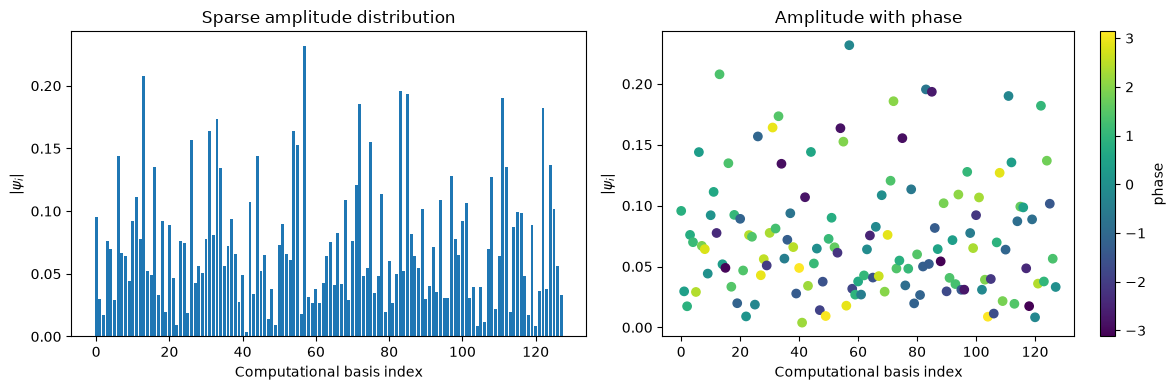

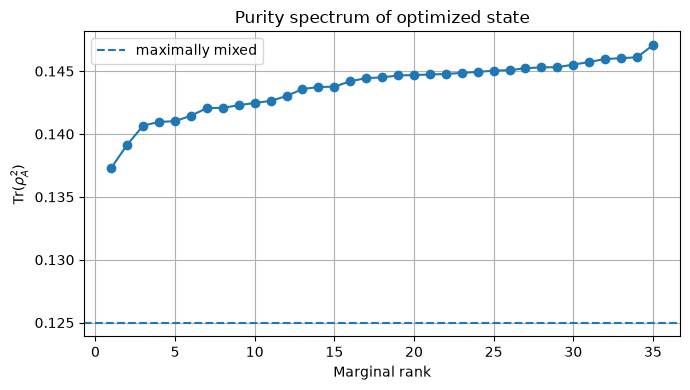

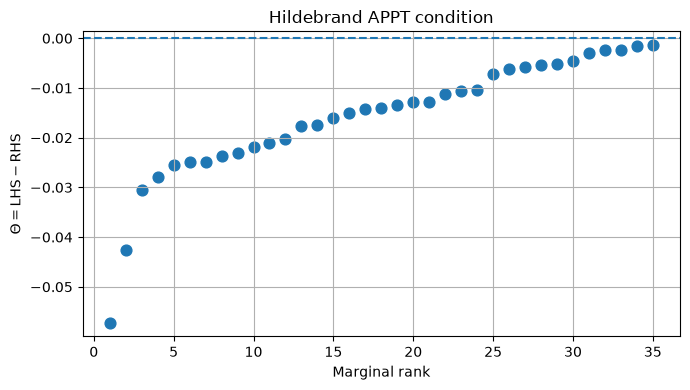

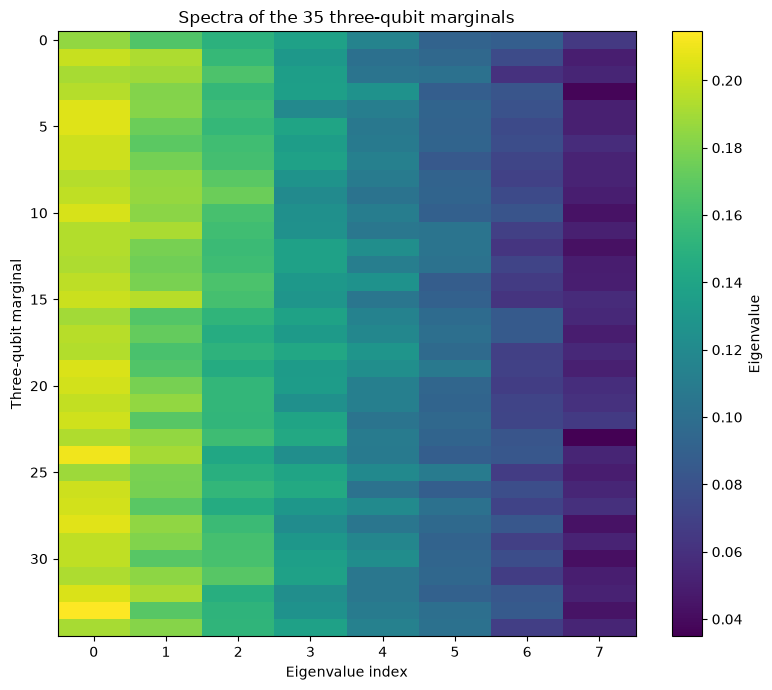

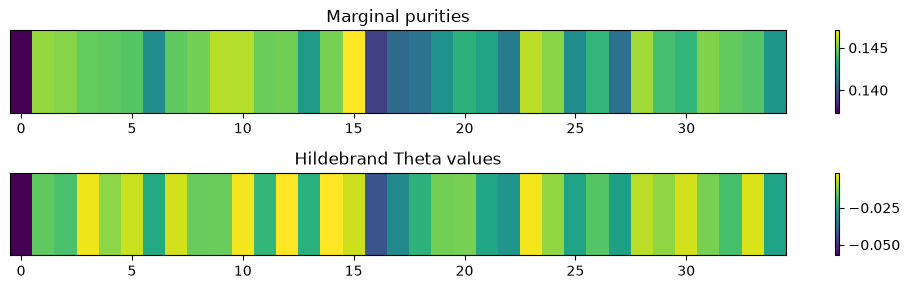


Closest to APPT violation:
     Marginal     Theta    Purity
3   (0, 1, 5) -0.002884  0.144770
10  (0, 3, 5) -0.002343  0.145963
23  (1, 4, 6) -0.002332  0.146099
12  (0, 4, 5) -0.001539  0.144934
14  (0, 5, 6) -0.001393  0.145074

Most mixed marginals:
     Marginal    Purity
0   (0, 1, 2)  0.137317
16  (1, 2, 4)  0.139156
17  (1, 2, 5)  0.140669
27  (2, 3, 6)  0.140963
18  (1, 2, 6)  0.141018


In [ ]:
# ============================================================
# COMPLETE PRESENTATION OF THE OPTIMIZED 7-QUBIT STATE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# ANALYZE ALL 35 THREE-QUBIT MARGINALS
# ============================================================

rows = []
all_spectra = []


for combo in combos:

    rho = get_3qubit_marginal(
        psi,
        combo,
        7
    )

    violation, lhs, rhs = hildebrand_violation(rho)

    purity = np.real(
        np.trace(rho @ rho)
    )

    theta = lhs-rhs

    eigs = np.sort(
        np.real(
            np.linalg.eigvalsh(rho)
        )
    )[::-1]


    all_spectra.append(eigs)


    rows.append({

        "Marginal": str(combo),

        "Purity": purity,

        "Theta": theta,

        "LHS": lhs,

        "RHS": rhs,

        "lambda_min": eigs[-1],

        "lambda_max": eigs[0],

        "PASS": theta <= 1e-7

    })


df = pd.DataFrame(rows)

all_spectra=np.array(all_spectra)



# ============================================================
# PRINT SUMMARY
# ============================================================

print("="*80)
print("OPTIMIZED STATE SUMMARY")
print("="*80)


print(
    f"APPT marginals: {df['PASS'].sum()}/35"
)


print("\nPurity statistics")
print(
    df["Purity"].describe()
)


print("\nTheta statistics (LHS-RHS)")
print(
    df["Theta"].describe()
)



# ============================================================
# LATEX TABLE
# ============================================================

print("\n\n% Copy table into LaTeX\n")


print(r"\begin{table}")
print(r"\centering")
print(r"\begin{tabular}{ccccccc}")
print(r"\hline")

print(
r"Marginal & Purity & $\Theta$ & LHS & RHS & "
r"$\lambda_{\min}$ & $\lambda_{\max}$ \\"
)

print(r"\hline")


for _,row in df.iterrows():

    print(
        f"{row['Marginal']} & "
        f"{row['Purity']:.3f} & "
        f"{row['Theta']:.3f} & "
        f"{row['LHS']:.3f} & "
        f"{row['RHS']:.3f} & "
        f"{row['lambda_min']:.3f} & "
        f"{row['lambda_max']:.3f} \\\\"
    )


print(r"\hline")
print(r"\end{tabular}")

print(
r"\caption{Properties of the 35 three-qubit marginals "
r"of the locally optimized sparse state. "
r"$\Theta=\mathrm{LHS}-\mathrm{RHS}$, with "
r"$\Theta\leq0$ satisfying the Hildebrand APPT condition.}"
)

print(
r"\label{tab:optimized_marginals}"
)

print(r"\end{table}")



# ============================================================
# FIGURE 1
# AMPLITUDE AND PHASE OF OPTIMIZED STATE
# ============================================================


fig,ax=plt.subplots(
    1,2,
    figsize=(12,4)
)


amp=np.abs(psi)

phase=np.angle(psi)



ax[0].bar(
    np.arange(len(psi)),
    amp
)

ax[0].set_xlabel(
    "Computational basis index"
)

ax[0].set_ylabel(
    r"$|\psi_i|$"
)

ax[0].set_title(
    "Sparse amplitude distribution"
)



sc=ax[1].scatter(
    np.arange(len(psi)),
    amp,
    c=phase,
    cmap="viridis"
)


plt.colorbar(
    sc,
    ax=ax[1],
    label="phase"
)


ax[1].set_xlabel(
    "Computational basis index"
)

ax[1].set_ylabel(
    r"$|\psi_i|$"
)

ax[1].set_title(
    "Amplitude with phase"
)


plt.tight_layout()
plt.show()



# ============================================================
# FIGURE 2
# PURITY DISTRIBUTION
# ============================================================


plt.figure(figsize=(7,4))


plt.plot(
    np.arange(1,36),
    np.sort(df["Purity"]),
    "o-"
)


plt.axhline(
    1/8,
    linestyle="--",
    label="maximally mixed"
)


plt.xlabel(
    "Marginal rank"
)

plt.ylabel(
    r"$\mathrm{Tr}(\rho_A^2)$"
)


plt.title(
    "Purity spectrum of optimized state"
)


plt.grid()
plt.legend()

plt.tight_layout()
plt.show()



# ============================================================
# FIGURE 3
# HILDEBRAND APPT MARGINS
# ============================================================


plt.figure(figsize=(7,4))


theta_sorted=np.sort(
    df["Theta"]
)


plt.scatter(
    np.arange(1,36),
    theta_sorted,
    s=60
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xlabel(
    "Marginal rank"
)


plt.ylabel(
    r"$\Theta=\mathrm{LHS}-\mathrm{RHS}$"
)


plt.title(
    "Hildebrand APPT condition"
)


plt.grid()

plt.tight_layout()

plt.show()



# ============================================================
# FIGURE 4
# EIGENVALUE HEATMAP
# ============================================================


plt.figure(figsize=(8,7))


plt.imshow(
    all_spectra,
    aspect="auto"
)


plt.colorbar(
    label="Eigenvalue"
)


plt.xlabel(
    "Eigenvalue index"
)

plt.ylabel(
    "Three-qubit marginal"
)


plt.title(
    "Spectra of the 35 three-qubit marginals"
)


plt.tight_layout()

plt.show()



# ============================================================
# FIGURE 5
# PURITY AND THETA HEATMAP
# ============================================================


fig,ax=plt.subplots(
    2,1,
    figsize=(10,3)
)


im1=ax[0].imshow(
    df["Purity"].values.reshape(1,-1),
    aspect="auto"
)


ax[0].set_title(
    "Marginal purities"
)

ax[0].set_yticks([])


plt.colorbar(
    im1,
    ax=ax[0]
)



im2=ax[1].imshow(
    df["Theta"].values.reshape(1,-1),
    aspect="auto"
)


ax[1].set_title(
    "Hildebrand Theta values"
)

ax[1].set_yticks([])


plt.colorbar(
    im2,
    ax=ax[1]
)


plt.tight_layout()

plt.show()



# ============================================================
# CRITICAL MARGINALS
# ============================================================


print("\nClosest to APPT violation:")
print(
    df.sort_values("Theta")
    [["Marginal","Theta","Purity"]]
    .tail(5)
)


print("\nMost mixed marginals:")
print(
    df.sort_values("Purity")
    [["Marginal","Purity"]]
    .head(5)
)

In [3]:
pip install pandas

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.9 MB 9.5 MB/s eta 0:00:01
   ---------------- ----------------------- 4.2/9.9 MB 10.7 MB/s eta 0:00:01
   -------------------------- ------------- 6.6/9.9 MB 11.0 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.9 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 11.6 MB/s  0:00:00

   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------


STATE SUMMARY
APPT marginals: 35/35

Purity statistics
count    35.000000
mean      0.143724
std       0.002137
min       0.137317
25%       0.142380
50%       0.144499
75%       0.145153
max       0.147061
Name: Purity, dtype: float64

Hildebrand gap statistics (RHS-LHS)
count    35.000000
mean      0.015820
std       0.012033
min       0.001393
25%       0.005903
50%       0.014067
75%       0.022419
max       0.057203
Name: Gap, dtype: float64

Lowest purity marginal
Triplet    (0, 1, 2)
Purity      0.137317
Gap         0.057203
LHS         0.185471
RHS         0.242673
Pass            True
Name: 0, dtype: object

Highest purity marginal
Triplet    (1, 2, 3)
Purity      0.147061
Gap         0.005724
LHS         0.199989
RHS         0.205713
Pass            True
Name: 15, dtype: object

Worst APPT margin
Triplet    (0, 5, 6)
Purity      0.145074
Gap         0.001393
LHS         0.196916
RHS         0.198309
Pass            True
Name: 14, dtype: object

Best APPT margin
Triplet    (0

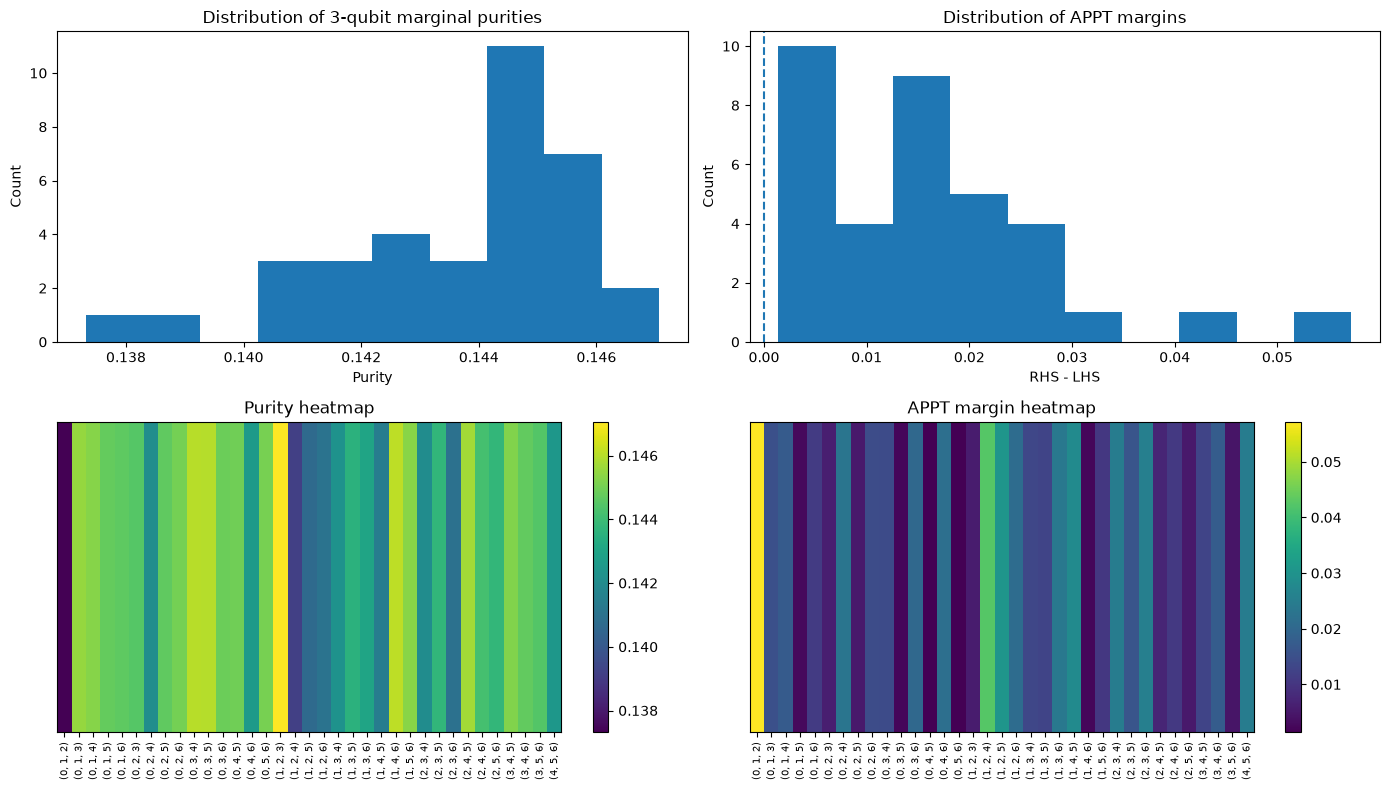


Saved detailed analysis to marginal_analysis.csv


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = np.loadtxt("as_search_state.txt")
psi = data[:, 0] + 1j * data[:, 1]

# ============================================================
# ANALYZE ALL 35 MARGINALS
# ============================================================

rows = []

for combo in combos:

    rho = get_3qubit_marginal(psi, combo, 7)

    violation, lhs, rhs = hildebrand_violation(rho)

    purity = np.real(np.trace(rho @ rho))

    gap = rhs - lhs

    rows.append({
        "Triplet": str(combo),
        "Purity": purity,
        "Gap": gap,
        "LHS": lhs,
        "RHS": rhs,
        "Pass": gap >= -1e-7
    })

df = pd.DataFrame(rows)

# ============================================================
# GLOBAL SUMMARY
# ============================================================

print("\n" + "="*70)
print("STATE SUMMARY")
print("="*70)

n_pass = int(df["Pass"].sum())

print(f"APPT marginals: {n_pass}/35")

print("\nPurity statistics")
print(df["Purity"].describe())

print("\nHildebrand gap statistics (RHS-LHS)")
print(df["Gap"].describe())

print("\nLowest purity marginal")
idx = df["Purity"].idxmin()
print(df.loc[idx])

print("\nHighest purity marginal")
idx = df["Purity"].idxmax()
print(df.loc[idx])

print("\nWorst APPT margin")
idx = df["Gap"].idxmin()
print(df.loc[idx])

print("\nBest APPT margin")
idx = df["Gap"].idxmax()
print(df.loc[idx])

# ============================================================
# FULL TABLE
# ============================================================

print("\n" + "="*70)
print("FULL TABLE")
print("="*70)

print(
    df.sort_values("Gap")
      .to_string(index=False)
)

# ============================================================
# WORST MARGINALS
# ============================================================

print("\n" + "="*70)
print("10 WORST MARGINALS")
print("="*70)

print(
    df.sort_values("Gap")
      [["Triplet","Gap","Purity"]]
      .head(10)
      .to_string(index=False)
)

# ============================================================
# BEST MARGINALS
# ============================================================

print("\n" + "="*70)
print("10 BEST MARGINALS")
print("="*70)

print(
    df.sort_values("Gap", ascending=False)
      [["Triplet","Gap","Purity"]]
      .head(10)
      .to_string(index=False)
)

# ============================================================
# PLOTS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# ------------------------------------------------------------
# Purity histogram
# ------------------------------------------------------------

axes[0,0].hist(df["Purity"], bins=10)

axes[0,0].set_title("Distribution of 3-qubit marginal purities")
axes[0,0].set_xlabel("Purity")
axes[0,0].set_ylabel("Count")

# ------------------------------------------------------------
# APPT margin histogram
# ------------------------------------------------------------

axes[0,1].hist(df["Gap"], bins=10)

axes[0,1].axvline(
    0,
    linestyle="--"
)

axes[0,1].set_title("Distribution of APPT margins")
axes[0,1].set_xlabel("RHS - LHS")
axes[0,1].set_ylabel("Count")

# ------------------------------------------------------------
# Purity heatmap
# ------------------------------------------------------------

im1 = axes[1,0].imshow(
    df["Purity"].values.reshape(1,-1),
    aspect="auto"
)

axes[1,0].set_title("Purity heatmap")
axes[1,0].set_yticks([])
axes[1,0].set_xticks(range(35))
axes[1,0].set_xticklabels(
    df["Triplet"],
    rotation=90,
    fontsize=7
)

plt.colorbar(
    im1,
    ax=axes[1,0]
)

# ------------------------------------------------------------
# APPT margin heatmap
# ------------------------------------------------------------

im2 = axes[1,1].imshow(
    df["Gap"].values.reshape(1,-1),
    aspect="auto"
)

axes[1,1].set_title("APPT margin heatmap")
axes[1,1].set_yticks([])
axes[1,1].set_xticks(range(35))
axes[1,1].set_xticklabels(
    df["Triplet"],
    rotation=90,
    fontsize=7
)

plt.colorbar(
    im2,
    ax=axes[1,1]
)

plt.tight_layout()
plt.show()

# ============================================================
# OPTIONAL: SAVE TABLE
# ============================================================

df.to_csv(
    "marginal_analysis.csv",
    index=False
)

print("\nSaved detailed analysis to marginal_analysis.csv")

STATE SUMMARY
APPT marginals: 35/35

Purity
count    35.000000
mean      0.143724
std       0.002137
min       0.137317
25%       0.142380
50%       0.144499
75%       0.145153
max       0.147061
Name: Purity, dtype: float64

APPT margin
count    35.000000
mean      0.015820
std       0.012033
min       0.001393
25%       0.005903
50%       0.014067
75%       0.022419
max       0.057203
Name: APPT margin, dtype: float64



% Copy this table directly into LaTeX

\begin{table}
\centering
\begin{tabular}{cccccc}
\hline
Marginal & Purity & $S_L$ & APPT margin & $\lambda_{\min}$ & $\lambda_{\max}$ \\
\hline
(0, 1, 2) & 0.137317 & 0.862683 & 5.720e-02 & 0.064691 & 0.185471 \\
(0, 1, 3) & 0.145513 & 0.854487 & 1.498e-02 & 0.050097 & 0.199364 \\
(0, 1, 4) & 0.145299 & 0.854701 & 1.740e-02 & 0.053768 & 0.191111 \\
(0, 1, 5) & 0.144770 & 0.855230 & 2.884e-03 & 0.037086 & 0.194231 \\
(0, 1, 6) & 0.144654 & 0.855346 & 1.114e-02 & 0.050685 & 0.205817 \\
(0, 2, 3) & 0.144499 & 0.855501 & 6.082e-03 &

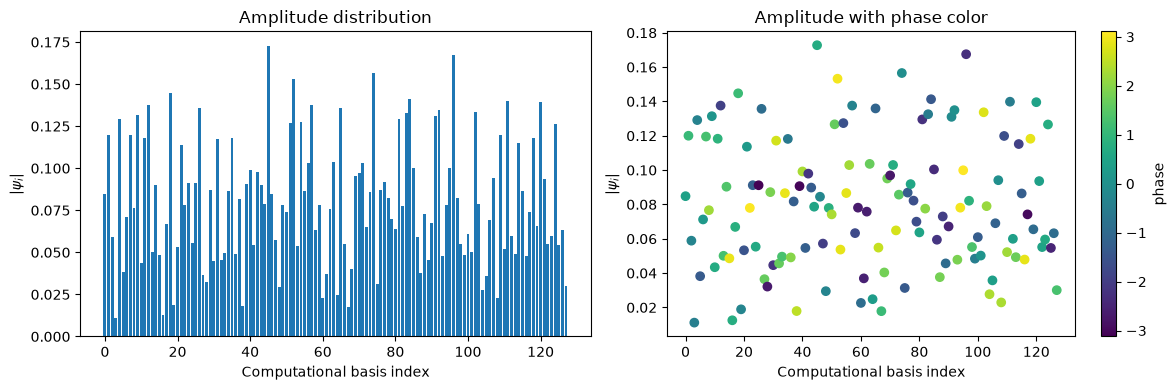

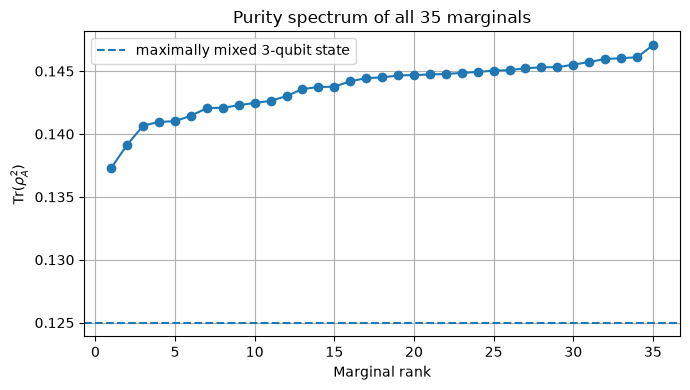

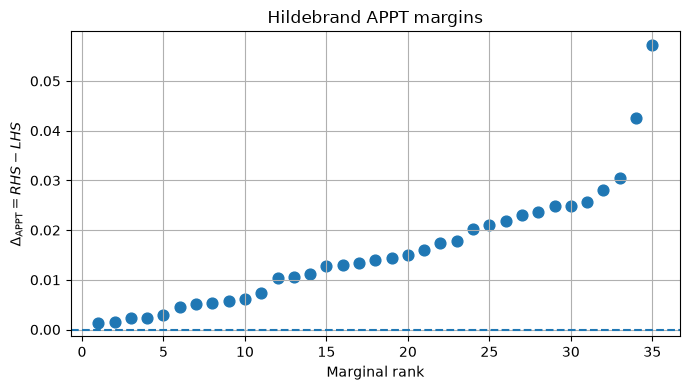

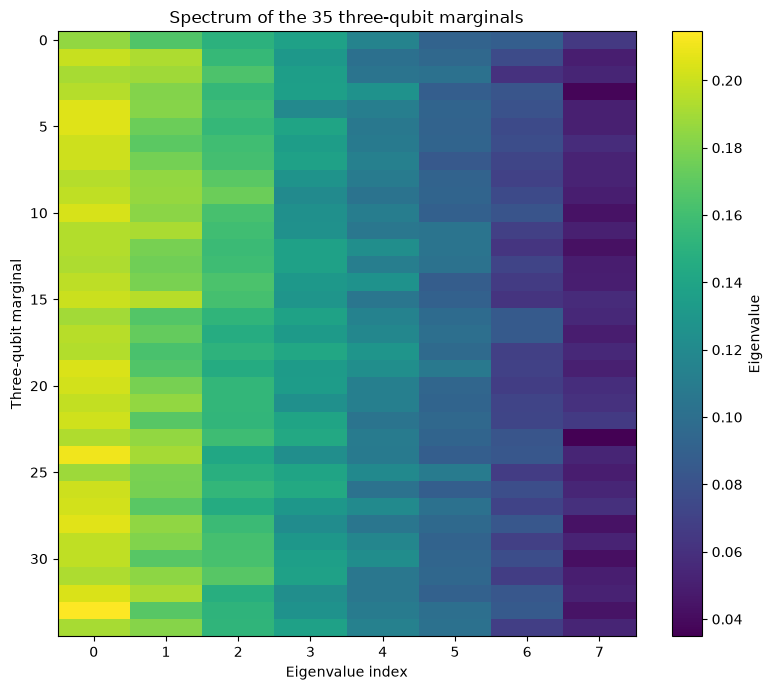

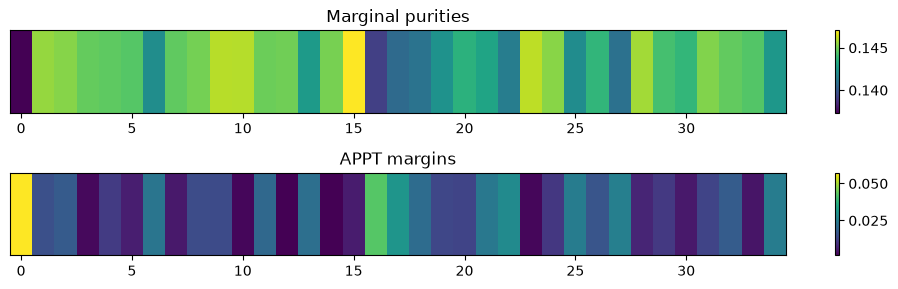


Worst APPT marginals:
     Marginal    Purity  APPT margin
14  (0, 5, 6)  0.145074     0.001393
12  (0, 4, 5)  0.144934     0.001539
23  (1, 4, 6)  0.146099     0.002332
10  (0, 3, 5)  0.145963     0.002343
3   (0, 1, 5)  0.144770     0.002884

Most mixed marginals:
     Marginal    Purity
0   (0, 1, 2)  0.137317
16  (1, 2, 4)  0.139156
17  (1, 2, 5)  0.140669
27  (2, 3, 6)  0.140963
18  (1, 2, 6)  0.141018


In [6]:
# ============================================================
# COMPLETE PRESENTATION OF A 7-QUBIT STATE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# ANALYZE ALL 35 THREE-QUBIT MARGINALS
# ============================================================

rows = []
all_spectra = []

for combo in combos:

    rho = get_3qubit_marginal(psi, combo, 7)

    violation, lhs, rhs = hildebrand_violation(rho)

    purity = np.real(np.trace(rho @ rho))

    gap = rhs - lhs

    eigs = np.sort(
        np.real(np.linalg.eigvalsh(rho))
    )[::-1]

    all_spectra.append(eigs)

    rows.append({
        "Marginal": str(combo),
        "Purity": purity,
        "Linear entropy": 1-purity,
        "APPT margin": gap,
        "LHS": lhs,
        "RHS": rhs,
        "lambda_min": eigs[-1],
        "lambda_max": eigs[0],
        "PASS": gap >= -1e-7
    })


df = pd.DataFrame(rows)

all_spectra = np.array(all_spectra)


# ============================================================
# PRINT SUMMARY
# ============================================================

print("="*80)
print("STATE SUMMARY")
print("="*80)

print(f"APPT marginals: {df['PASS'].sum()}/35")

print("\nPurity")
print(df["Purity"].describe())

print("\nAPPT margin")
print(df["APPT margin"].describe())


# ============================================================
# LATEX TABLE FOR PAPER
# ============================================================

print("\n\n")
print("% Copy this table directly into LaTeX")
print()

print(r"\begin{table}")
print(r"\centering")
print(r"\begin{tabular}{cccccc}")
print(r"\hline")
print(
    r"Marginal & Purity & $S_L$ & APPT margin & "
    r"$\lambda_{\min}$ & $\lambda_{\max}$ \\"
)
print(r"\hline")

for _, row in df.iterrows():

    print(
        f"{row['Marginal']} & "
        f"{row['Purity']:.6f} & "
        f"{row['Linear entropy']:.6f} & "
        f"{row['APPT margin']:.3e} & "
        f"{row['lambda_min']:.6f} & "
        f"{row['lambda_max']:.6f} \\\\"
    )

print(r"\hline")
print(r"\end{tabular}")
print(r"\caption{Properties of the 35 three-qubit marginals.}")
print(r"\label{tab:marginals}")
print(r"\end{table}")


# ============================================================
# FIGURE 1: AMPLITUDE AND PHASE OF THE STATE
# ============================================================

fig, ax = plt.subplots(
    1,2,
    figsize=(12,4)
)

amp = np.abs(psi)
phase = np.angle(psi)


ax[0].bar(
    np.arange(len(psi)),
    amp
)

ax[0].set_xlabel("Computational basis index")
ax[0].set_ylabel(r"$|\psi_i|$")
ax[0].set_title("Amplitude distribution")


sc = ax[1].scatter(
    np.arange(len(psi)),
    amp,
    c=phase,
    cmap="viridis"
)

plt.colorbar(
    sc,
    ax=ax[1],
    label="phase"
)

ax[1].set_xlabel("Computational basis index")
ax[1].set_ylabel(r"$|\psi_i|$")
ax[1].set_title("Amplitude with phase color")

plt.tight_layout()
plt.show()



# ============================================================
# FIGURE 2: SORTED PURITIES
# ============================================================

plt.figure(figsize=(7,4))

plt.plot(
    np.arange(1,36),
    np.sort(df["Purity"]),
    "o-"
)

plt.axhline(
    1/8,
    linestyle="--",
    label="maximally mixed 3-qubit state"
)

plt.xlabel("Marginal rank")
plt.ylabel(r"$\mathrm{Tr}(\rho_A^2)$")

plt.title("Purity spectrum of all 35 marginals")

plt.grid()
plt.legend()

plt.tight_layout()
plt.show()



# ============================================================
# FIGURE 3: APPT ROBUSTNESS
# ============================================================

plt.figure(figsize=(7,4))

gap_sorted = np.sort(df["APPT margin"])

plt.scatter(
    np.arange(1,36),
    gap_sorted,
    s=60
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Marginal rank")
plt.ylabel(r"$\Delta_{\rm APPT}=RHS-LHS$")

plt.title("Hildebrand APPT margins")

plt.grid()

plt.tight_layout()
plt.show()



# ============================================================
# FIGURE 4: EIGENVALUE HEATMAP
# ============================================================

plt.figure(figsize=(8,7))

plt.imshow(
    all_spectra,
    aspect="auto"
)

plt.colorbar(
    label="Eigenvalue"
)

plt.xlabel("Eigenvalue index")
plt.ylabel("Three-qubit marginal")

plt.title(
    "Spectrum of the 35 three-qubit marginals"
)

plt.tight_layout()
plt.show()



# ============================================================
# FIGURE 5: PURITY AND APPT HEATMAPS
# ============================================================

fig,ax = plt.subplots(
    2,1,
    figsize=(10,3)
)


im1=ax[0].imshow(
    df["Purity"].values.reshape(1,-1),
    aspect="auto"
)

ax[0].set_title("Marginal purities")
ax[0].set_yticks([])

plt.colorbar(
    im1,
    ax=ax[0],
    orientation="vertical"
)


im2=ax[1].imshow(
    df["APPT margin"].values.reshape(1,-1),
    aspect="auto"
)

ax[1].set_title("APPT margins")
ax[1].set_yticks([])

plt.colorbar(
    im2,
    ax=ax[1],
    orientation="vertical"
)


plt.tight_layout()
plt.show()



# ============================================================
# FIND MOST CRITICAL MARGINALS
# ============================================================

print("\nWorst APPT marginals:")
print(
    df.sort_values("APPT margin")
    [["Marginal","Purity","APPT margin"]]
    .head(5)
)


print("\nMost mixed marginals:")
print(
    df.sort_values("Purity")
    [["Marginal","Purity"]]
    .head(5)
)

In [7]:
# ============================================================
# FULL LATEX TABLE OUTPUT (COPY-PASTE VERSION)
# ============================================================

latex_table = []

latex_table.append(r"\begin{table}")
latex_table.append(r"\centering")
latex_table.append(r"\begin{tabular}{cccccc}")
latex_table.append(r"\hline")
latex_table.append(
    r"Marginal & Purity & $S_L$ & APPT margin & "
    r"$\lambda_{\min}$ & $\lambda_{\max}$ \\"
)
latex_table.append(r"\hline")


for _, row in df.iterrows():

    latex_table.append(
        f"{row['Marginal']} & "
        f"{row['Purity']:.6f} & "
        f"{row['Linear entropy']:.6f} & "
        f"{row['APPT margin']:.6e} & "
        f"{row['lambda_min']:.6f} & "
        f"{row['lambda_max']:.6f} \\\\"
    )


latex_table.append(r"\hline")
latex_table.append(r"\end{tabular}")
latex_table.append(
    r"\caption{Properties of all three-qubit marginals of the 7-qubit state.}"
)
latex_table.append(r"\label{tab:3qubit_marginals}")
latex_table.append(r"\end{table}")


# join everything into one output string
latex_output = "\n".join(latex_table)


# force full display
from IPython.display import display, Markdown

display(
    Markdown(
        "```latex\n" + latex_output + "\n```"
    )
)

```latex
\begin{table}
\centering
\begin{tabular}{cccccc}
\hline
Marginal & Purity & $S_L$ & APPT margin & $\lambda_{\min}$ & $\lambda_{\max}$ \\
\hline
(0, 1, 2) & 0.137317 & 0.862683 & 5.720265e-02 & 0.064691 & 0.185471 \\
(0, 1, 3) & 0.145513 & 0.854487 & 1.497666e-02 & 0.050097 & 0.199364 \\
(0, 1, 4) & 0.145299 & 0.854701 & 1.739823e-02 & 0.053768 & 0.191111 \\
(0, 1, 5) & 0.144770 & 0.855230 & 2.883735e-03 & 0.037086 & 0.194231 \\
(0, 1, 6) & 0.144654 & 0.855346 & 1.113784e-02 & 0.050685 & 0.205817 \\
(0, 2, 3) & 0.144499 & 0.855501 & 6.081715e-03 & 0.050730 & 0.205947 \\
(0, 2, 4) & 0.142083 & 0.857917 & 2.301130e-02 & 0.057995 & 0.200865 \\
(0, 2, 5) & 0.144686 & 0.855314 & 5.174106e-03 & 0.052718 & 0.201126 \\
(0, 2, 6) & 0.145039 & 0.854961 & 1.429842e-02 & 0.052699 & 0.194599 \\
(0, 3, 4) & 0.146030 & 0.853970 & 1.406693e-02 & 0.049704 & 0.197414 \\
(0, 3, 5) & 0.145963 & 0.854037 & 2.342947e-03 & 0.043371 & 0.203841 \\
(0, 3, 6) & 0.144860 & 0.855140 & 2.027885e-02 & 0.050423 & 0.193677 \\
(0, 4, 5) & 0.144934 & 0.855066 & 1.538559e-03 & 0.042707 & 0.194181 \\
(0, 4, 6) & 0.142633 & 0.857367 & 2.182688e-02 & 0.049412 & 0.192223 \\
(0, 5, 6) & 0.145074 & 0.854926 & 1.392913e-03 & 0.050022 & 0.196916 \\
(1, 2, 3) & 0.147061 & 0.852939 & 5.724310e-03 & 0.057210 & 0.199989 \\
(1, 2, 4) & 0.139156 & 0.860844 & 4.251762e-02 & 0.055277 & 0.189745 \\
(1, 2, 5) & 0.140669 & 0.859331 & 3.046521e-02 & 0.048968 & 0.195424 \\
(1, 2, 6) & 0.141018 & 0.858982 & 2.102307e-02 & 0.055429 & 0.194170 \\
(1, 3, 4) & 0.142290 & 0.857710 & 1.332372e-02 & 0.050864 & 0.204177 \\
(1, 3, 5) & 0.143576 & 0.856424 & 1.291034e-02 & 0.058037 & 0.202586 \\
(1, 3, 6) & 0.143019 & 0.856981 & 2.366926e-02 & 0.060752 & 0.198060 \\
(1, 4, 5) & 0.141459 & 0.858541 & 2.800694e-02 & 0.065051 & 0.201904 \\
(1, 4, 6) & 0.146099 & 0.853901 & 2.331660e-03 & 0.034834 & 0.193268 \\
(1, 5, 6) & 0.145315 & 0.854685 & 1.037483e-02 & 0.053502 & 0.210710 \\
(2, 3, 4) & 0.142060 & 0.857940 & 2.491222e-02 & 0.048900 & 0.188313 \\
(2, 3, 5) & 0.143735 & 0.856265 & 1.606704e-02 & 0.054237 & 0.200674 \\
(2, 3, 6) & 0.140963 & 0.859037 & 2.557884e-02 & 0.060045 & 0.202108 \\
(2, 4, 5) & 0.145728 & 0.854272 & 7.254229e-03 & 0.043648 & 0.206499 \\
(2, 4, 6) & 0.144193 & 0.855807 & 1.065510e-02 & 0.052806 & 0.197517 \\
(2, 5, 6) & 0.143764 & 0.856236 & 5.285461e-03 & 0.042174 & 0.197385 \\
(3, 4, 5) & 0.145232 & 0.854768 & 1.287883e-02 & 0.050103 & 0.192273 \\
(3, 4, 6) & 0.144735 & 0.855265 & 1.772395e-02 & 0.052302 & 0.204086 \\
(3, 5, 6) & 0.144444 & 0.855556 & 4.519529e-03 & 0.044436 & 0.214572 \\
(4, 5, 6) & 0.142471 & 0.857529 & 2.486057e-02 & 0.053205 & 0.191045 \\
\hline
\end{tabular}
\caption{Properties of all three-qubit marginals of the 7-qubit state.}
\label{tab:3qubit_marginals}
\end{table}
```

In [8]:
# ============================================================
# FULL LATEX TABLE FOR PAPER
# Rounded to 3 decimals
# ============================================================

latex_table = []

latex_table.append(r"\begin{table}")
latex_table.append(r"\centering")
latex_table.append(r"\begin{tabular}{cccccccc}")
latex_table.append(r"\hline")

latex_table.append(
    r"Marginal & Purity & $\Theta$ & LHS & RHS & "
    r"$\lambda_{\min}$ & $\lambda_{\max}$ & Rank \\"
)

latex_table.append(r"\hline")


for _, row in df.iterrows():

    latex_table.append(
        f"{row['Marginal']} & "
        f"{row['Purity']:.3f} & "
        f"{(row['LHS']-row['RHS']):.3f} & "
        f"{row['LHS']:.3f} & "
        f"{row['RHS']:.3f} & "
        f"{row['lambda_min']:.3f} & "
        f"{row['lambda_max']:.3f} & "
        f"{8} \\\\"
    )


latex_table.append(r"\hline")
latex_table.append(r"\end{tabular}")

latex_table.append(
r"\caption{Spectral and Hildebrand properties of the 35 three-qubit marginals. "
r"The quantity $\Theta=\mathrm{LHS}-\mathrm{RHS}$ determines the APPT condition: "
r"$\Theta\leq0$ indicates satisfaction of the Hildebrand criterion.}"
)

latex_table.append(
r"\label{tab:hildebrand_marginals}"
)

latex_table.append(r"\end{table}")


latex_output = "\n".join(latex_table)


from IPython.display import display, Markdown

display(
    Markdown(
        "```latex\n" + latex_output + "\n```"
    )
)

```latex
\begin{table}
\centering
\begin{tabular}{cccccccc}
\hline
Marginal & Purity & $\Theta$ & LHS & RHS & $\lambda_{\min}$ & $\lambda_{\max}$ & Rank \\
\hline
(0, 1, 2) & 0.137 & -0.057 & 0.185 & 0.243 & 0.065 & 0.185 & 8 \\
(0, 1, 3) & 0.146 & -0.015 & 0.199 & 0.214 & 0.050 & 0.199 & 8 \\
(0, 1, 4) & 0.145 & -0.017 & 0.191 & 0.209 & 0.054 & 0.191 & 8 \\
(0, 1, 5) & 0.145 & -0.003 & 0.194 & 0.197 & 0.037 & 0.194 & 8 \\
(0, 1, 6) & 0.145 & -0.011 & 0.206 & 0.217 & 0.051 & 0.206 & 8 \\
(0, 2, 3) & 0.144 & -0.006 & 0.206 & 0.212 & 0.051 & 0.206 & 8 \\
(0, 2, 4) & 0.142 & -0.023 & 0.201 & 0.224 & 0.058 & 0.201 & 8 \\
(0, 2, 5) & 0.145 & -0.005 & 0.201 & 0.206 & 0.053 & 0.201 & 8 \\
(0, 2, 6) & 0.145 & -0.014 & 0.195 & 0.209 & 0.053 & 0.195 & 8 \\
(0, 3, 4) & 0.146 & -0.014 & 0.197 & 0.211 & 0.050 & 0.197 & 8 \\
(0, 3, 5) & 0.146 & -0.002 & 0.204 & 0.206 & 0.043 & 0.204 & 8 \\
(0, 3, 6) & 0.145 & -0.020 & 0.194 & 0.214 & 0.050 & 0.194 & 8 \\
(0, 4, 5) & 0.145 & -0.002 & 0.194 & 0.196 & 0.043 & 0.194 & 8 \\
(0, 4, 6) & 0.143 & -0.022 & 0.192 & 0.214 & 0.049 & 0.192 & 8 \\
(0, 5, 6) & 0.145 & -0.001 & 0.197 & 0.198 & 0.050 & 0.197 & 8 \\
(1, 2, 3) & 0.147 & -0.006 & 0.200 & 0.206 & 0.057 & 0.200 & 8 \\
(1, 2, 4) & 0.139 & -0.043 & 0.190 & 0.232 & 0.055 & 0.190 & 8 \\
(1, 2, 5) & 0.141 & -0.030 & 0.195 & 0.226 & 0.049 & 0.195 & 8 \\
(1, 2, 6) & 0.141 & -0.021 & 0.194 & 0.215 & 0.055 & 0.194 & 8 \\
(1, 3, 4) & 0.142 & -0.013 & 0.204 & 0.218 & 0.051 & 0.204 & 8 \\
(1, 3, 5) & 0.144 & -0.013 & 0.203 & 0.215 & 0.058 & 0.203 & 8 \\
(1, 3, 6) & 0.143 & -0.024 & 0.198 & 0.222 & 0.061 & 0.198 & 8 \\
(1, 4, 5) & 0.141 & -0.028 & 0.202 & 0.230 & 0.065 & 0.202 & 8 \\
(1, 4, 6) & 0.146 & -0.002 & 0.193 & 0.196 & 0.035 & 0.193 & 8 \\
(1, 5, 6) & 0.145 & -0.010 & 0.211 & 0.221 & 0.054 & 0.211 & 8 \\
(2, 3, 4) & 0.142 & -0.025 & 0.188 & 0.213 & 0.049 & 0.188 & 8 \\
(2, 3, 5) & 0.144 & -0.016 & 0.201 & 0.217 & 0.054 & 0.201 & 8 \\
(2, 3, 6) & 0.141 & -0.026 & 0.202 & 0.228 & 0.060 & 0.202 & 8 \\
(2, 4, 5) & 0.146 & -0.007 & 0.206 & 0.214 & 0.044 & 0.206 & 8 \\
(2, 4, 6) & 0.144 & -0.011 & 0.198 & 0.208 & 0.053 & 0.198 & 8 \\
(2, 5, 6) & 0.144 & -0.005 & 0.197 & 0.203 & 0.042 & 0.197 & 8 \\
(3, 4, 5) & 0.145 & -0.013 & 0.192 & 0.205 & 0.050 & 0.192 & 8 \\
(3, 4, 6) & 0.145 & -0.018 & 0.204 & 0.222 & 0.052 & 0.204 & 8 \\
(3, 5, 6) & 0.144 & -0.005 & 0.215 & 0.219 & 0.044 & 0.215 & 8 \\
(4, 5, 6) & 0.142 & -0.025 & 0.191 & 0.216 & 0.053 & 0.191 & 8 \\
\hline
\end{tabular}
\caption{Spectral and Hildebrand properties of the 35 three-qubit marginals. The quantity $\Theta=\mathrm{LHS}-\mathrm{RHS}$ determines the APPT condition: $\Theta\leq0$ indicates satisfaction of the Hildebrand criterion.}
\label{tab:hildebrand_marginals}
\end{table}
```

In [21]:
import numpy as np
from itertools import combinations
from scipy.optimize import minimize

# --- Core Physics Functions ---

def get_3qubit_marginal(psi_vec, indices, n_qubits=7):
    """Computes the reduced density matrix rho for a subset of qubits."""
    state = psi_vec.reshape([2]*n_qubits)
    all_indices = set(range(n_qubits))
    trace_out = list(all_indices - set(indices))
    # Partial trace via tensor contraction
    rho = np.tensordot(state, np.conj(state), axes=(trace_out, trace_out))
    return rho.reshape(8, 8)

def hildebrand_check(rho):
    """
    For 2 x L systems (like 3 qubits), APPT = ASEP.
    Condition: l1 <= l7 + 2*sqrt(l6 * l8)
    """
    evals = np.sort(np.linalg.eigvalsh(rho))[::-1]
    evals = np.clip(evals, 1e-15, None) # Numerical stability
    
    l1 = evals[0]
    l6 = evals[5]
    l7 = evals[6]
    l8 = evals[7]
    
    rhs = l7 + 2 * np.sqrt(l6 * l8)
    violation = max(0, l1 - rhs)
    return violation, l1, rhs

# --- Optimization Engine ---

def objective_function(params, n_qubits, combos):
    n_dim = 2**n_qubits
    # Reconstruct complex state
    psi = params[:n_dim] + 1j * params[n_dim:]
    psi /= np.linalg.norm(psi)
    
    total_violation = 0
    for combo in combos:
        rho = get_3qubit_marginal(psi, combo, n_qubits)
        violation, _, _ = hildebrand_check(rho)
        # Use squared violation to provide a smoother gradient for the optimizer
        total_violation += violation**2 
    
    return total_violation

def run_targeted_search(n_qubits=7):
    combos = list(combinations(range(n_qubits), 3))
    n_dim = 2**n_qubits
    
    # Random initialization
    init_psi = np.random.randn(n_dim) + 1j*np.random.randn(n_dim)
    init_psi /= np.linalg.norm(init_psi)
    init_params = np.concatenate([init_psi.real, init_psi.imag])
    
    print(f"--- Searching for 7-qubit state with all {len(combos)} marginals being ASEP ---")
    
    # We use L-BFGS-B; for 7 qubits this is 256 variables (128 real + 128 imag)
    res = minimize(objective_function, init_params, args=(n_qubits, combos), 
                   method='L-BFGS-B', options={'maxiter': 200, 'ftol': 1e-12})
    
    final_psi = res.x[:n_dim] + 1j * res.x[n_dim:]
    return final_psi / np.linalg.norm(final_psi), combos

# --- Execution and Reporting ---

if __name__ == "__main__":
    N = 7
    # 1. Search
    final_psi, combos = run_targeted_search(N)
    
    # 2. Save
    np.savetxt("asep_marginal_state.txt", np.column_stack([final_psi.real, final_psi.imag]))
    
    # 3. Validation Table
    print(f"\n{'Triplet':<12} | {'ASEP/APPT':<10} | {'LHS (λ1)':<10} | {'RHS Bound':<10} | {'Purity':<8}")
    print("-" * 70)
    
    success_count = 0
    for combo in combos:
        rho = get_3qubit_marginal(final_psi, combo, N)
        violation, l1, rhs = hildebrand_check(rho)
        purity = np.real(np.trace(rho @ rho))
        
        # Using a small epsilon for numerical float precision
        is_asep = violation < 1e-8
        status = "YES" if is_asep else "NO"
        if is_asep: success_count += 1
        
        # Displaying subset of results to keep output clean
        if combo[0] < 2: # Show a representative sample
            print(f"{str(combo):<12} | {status:<10} | {l1:.6f}   | {rhs:.6f}   | {purity:.5f}")

    print("-" * 70)
    print(f"Final Result: {success_count}/35 marginals are Absolutely Separable.")
    
    if success_count == 35:
        print("\n[SUCCESS] Found a 7-qubit state satisfying all ASEP marginal conditions!")
    else:
        print("\n[PARTIAL] The optimizer reached a local minimum. Try running again.")

--- Searching for 7-qubit state with all 35 marginals being ASEP ---

Triplet      | ASEP/APPT  | LHS (λ1)   | RHS Bound  | Purity  
----------------------------------------------------------------------
(0, 1, 2)    | YES        | 0.205268   | 0.208487   | 0.14453
(0, 1, 3)    | YES        | 0.197809   | 0.197851   | 0.14779
(0, 1, 4)    | YES        | 0.204069   | 0.204787   | 0.14593
(0, 1, 5)    | YES        | 0.191783   | 0.200166   | 0.14448
(0, 1, 6)    | YES        | 0.203800   | 0.203869   | 0.14605
(0, 2, 3)    | YES        | 0.199650   | 0.199697   | 0.14852
(0, 2, 4)    | YES        | 0.196483   | 0.196595   | 0.14807
(0, 2, 5)    | YES        | 0.193057   | 0.193105   | 0.14589
(0, 2, 6)    | YES        | 0.195011   | 0.195109   | 0.14575
(0, 3, 4)    | YES        | 0.194495   | 0.198441   | 0.14381
(0, 3, 5)    | YES        | 0.200858   | 0.205457   | 0.14484
(0, 3, 6)    | YES        | 0.196009   | 0.216538   | 0.14482
(0, 4, 5)    | YES        | 0.199764   | 0.199911   

In [1]:


import numpy as np
from itertools import combinations
from scipy.optimize import minimize

def get_marginal(psi_vec, indices, n_qubits):
    """Partial trace to get the reduced density matrix of specified qubits."""
    state = psi_vec.reshape([2] * n_qubits)
    all_indices = set(range(n_qubits))
    trace_out = list(all_indices - set(indices))
    # Contract indices to trace out
    rho = np.tensordot(state, np.conj(state), axes=(trace_out, trace_out))
    dim_k = 2**len(indices)
    return rho.reshape(dim_k, dim_k)

def hildebrand_data(rho, k):
    """
    Checks the 1-vs-rest ASEP condition (Hildebrand spectral condition).
    For a 2 x L system (where L = 2^(k-1)):
    Condition: l_1 <= l_{D-1} + 2*sqrt(l_{D-2} * l_D)
    """
    D = 2**k
    evals = np.sort(np.linalg.eigvalsh(rho))[::-1]
    evals = np.clip(evals, 1e-15, None)
    
    # Map indices for the 2 x L spectral bound
    l1 = evals[0]          # Largest eigenvalue
    l_dm2 = evals[D-3]     # Third smallest
    l_dm1 = evals[D-2]     # Second smallest
    l_d = evals[D-1]       # Smallest
    
    rhs = l_dm1 + 2 * np.sqrt(l_dm2 * l_d)
    violation = max(0, l1 - rhs)
    return violation, l1, rhs

# --- Optimization ---

def objective_function(params, n, k, combos):
    n_dim = 2**n
    psi = params[:n_dim] + 1j * params[n_dim:]
    psi /= np.linalg.norm(psi)
    
    total_violation = 0
    for combo in combos:
        rho = get_marginal(psi, combo, n)
        violation, _, _ = hildebrand_data(rho, k)
        total_violation += violation**2 # Quadratic penalty
    return total_violation

def perform_search(n):
    k = n // 2
    combos = list(combinations(range(n), k))
    n_dim = 2**n
    
    # Random starting state
    init_psi = np.random.randn(n_dim) + 1j*np.random.randn(n_dim)
    init_psi /= np.linalg.norm(init_psi)
    init_params = np.concatenate([init_psi.real, init_psi.imag])
    
    print(f"--- Optimizing {n}-qubit state: {k}-qubit marginals ({len(combos)} total) ---")
    res = minimize(objective_function, init_params, args=(n, k, combos), 
                   method='L-BFGS-B', options={'maxiter': 200, 'ftol': 1e-11}) 
    # maxiter: I needed 200 for 7 qubits, 10000 for 8 qubits (and didn't find for 8 qubits)
    
    final_psi = res.x[:n_dim] + 1j * res.x[n_dim:]
    return final_psi / np.linalg.norm(final_psi), k, combos

# --- I/O and Reporting ---

def save_state(psi, filename):
    """Saves complex state as a simple flat float array."""
    np.savetxt(filename, psi.view(float))

def load_state(filename):
    """Loads flat float array and reconstructs complex vector."""
    data = np.loadtxt(filename)
    return data.view(complex)

def print_full_report(psi, n, k, combos):
    print(f"\nVerification for n={n}, k={k}: All {len(combos)} Reductions")
    header = f"{'Marginal Indices':<18} | {'1-vs-rest ASEP':<15} | {'LHS (λ1)':<10} | {'RHS Bound':<10} | {'Purity'}"
    print(header)
    print("-" * len(header))
    
    count = 0
    for combo in combos:
        rho = get_marginal(psi, combo, n)
        violation, l1, rhs = hildebrand_data(rho, k)
        purity = np.real(np.trace(rho @ rho))
        
        is_asep = violation < 1e-8
        if is_asep: count += 1
        
        status = "YES" if is_asep else "NO"
        print(f"{str(combo):<18} | {status:<15} | {l1:.6f}   | {rhs:.6f}   | {purity:.5f}")

    print("-" * len(header))
    print(f"Final Score: {count}/{len(combos)} marginals are 1-vs-rest ASEP.")

# --- Main Execution ---

if __name__ == "__main__":
    # USER PARAMETER: Choose n qubits
    N = 7 
    filename = f"State_{N}.txt"
    
    # 1. Search for a state satisfying the condition
    optimized_psi, k_val, all_combos = perform_search(N)
    
    # 2. Save the final state to the dynamic .txt file
    save_state(optimized_psi, filename)
    print(f"\n[FILE] State saved as a flat array in {filename}")
    
    # 3. Load it back and perform the verification test
    loaded_psi = load_state(filename)
    print_full_report(loaded_psi, N, k_val, all_combos)

--- Optimizing 7-qubit state: 3-qubit marginals (35 total) ---

[FILE] State saved as a flat array in State_7.txt

Verification for n=7, k=3: All 35 Reductions
Marginal Indices   | 1-vs-rest ASEP  | LHS (λ1)   | RHS Bound  | Purity
-----------------------------------------------------------------------
(0, 1, 2)          | YES             | 0.188946   | 0.193402   | 0.14587
(0, 1, 3)          | YES             | 0.201246   | 0.212565   | 0.14288
(0, 1, 4)          | YES             | 0.197783   | 0.209877   | 0.14408
(0, 1, 5)          | YES             | 0.211112   | 0.215541   | 0.14494
(0, 1, 6)          | YES             | 0.195088   | 0.202882   | 0.14421
(0, 2, 3)          | YES             | 0.204472   | 0.219381   | 0.14197
(0, 2, 4)          | YES             | 0.195129   | 0.213514   | 0.14290
(0, 2, 5)          | YES             | 0.197504   | 0.207544   | 0.14453
(0, 2, 6)          | YES             | 0.211866   | 0.229795   | 0.14330
(0, 3, 4)          | YES             | 

In [39]:
T = 10 # Number of trials
found = False
N=8
for i in range(T):
    psi, k, combos = perform_search(N)
    # Check if all violations are below threshold
    if all(hildebrand_data(get_marginal(psi, c, N), k)[0] < 1e-8 for c in combos):
        save_state(psi, f"final_state_{N}.txt")
        found = True
        break

print(f"Result: {'YES' if found else 'NO'}")

--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
--- Optimizing 8-qubit state: 4-qubit marginals (70 total) ---
Result: NO


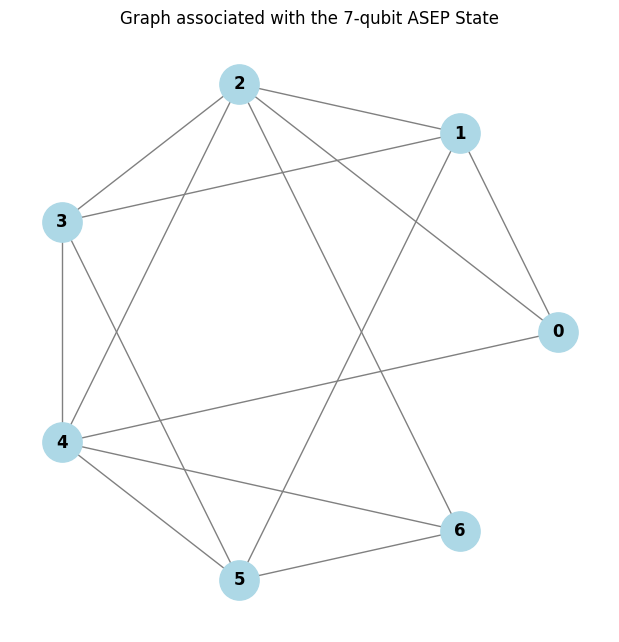

First 8 coefficients of the complex state vector:
[ 0.08838835+0.j  0.08838835+0.j  0.08838835+0.j -0.08838835+0.j
  0.08838835+0.j -0.08838835+0.j -0.08838835+0.j -0.08838835+0.j]


In [5]:
# Now we take a successful state and write it as an LU-equivalent graph state (hint only)
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from itertools import product

# 1. Define the Adjacency Matrix
# This is a circulant matrix where connections are at offsets 1, 2, and 4
A = np.array([
    [0, 1, 1, 0, 1, 0, 0],
    [1, 0, 1, 1, 0, 1, 0],
    [1, 1, 0, 1, 1, 0, 1],
    [0, 1, 1, 0, 1, 1, 0],
    [1, 0, 1, 1, 0, 1, 1],
    [0, 1, 0, 1, 1, 0, 1],
    [0, 0, 1, 0, 1, 1, 0]
])

# 2. Draw the Graph
def draw_graphstate(adj_matrix):
    G = nx.from_numpy_array(adj_matrix)
    pos = nx.circular_layout(G)
    plt.figure(figsize=(6, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightblue', 
            edge_color='gray', node_size=800, font_weight='bold')
    plt.show()

draw_graphstate(A)

# 3. Write the Graph State associated as a 7-qubit complex array
def generate_graph_state(adj_matrix):
    n = len(adj_matrix)
    num_states = 2**n
    # Start with the |+> ^n state (uniform superposition)
    # Each coefficient is 1/sqrt(2^n)
    state = np.ones(num_states, dtype=complex) / np.sqrt(num_states)
    
    # The phase of each basis state |x> is (-1)^(0.5 * x.T @ A @ x)
    # This corresponds to applying a CZ gate for every edge in the graph
    for i in range(num_states):
        # Convert index to bitstring (binary vector x)
        x = np.array([int(b) for b in bin(i)[2:].zfill(n)])
        
        # Calculate the phase: sum of x_i * x_j for all edges (i, j)
        # We only need the upper triangle of A to avoid double counting edges
        edges_count = 0
        for u in range(n):
            for v in range(u + 1, n):
                if adj_matrix[u, v] == 1 and x[u] == 1 and x[v] == 1:
                    edges_count += 1
        
        if edges_count % 2 == 1:
            state[i] *= -1
            
    return state

graph_state_vector = generate_graph_state(A)

# Output first 8 coefficients to verify
print("First 8 coefficients of the complex state vector:")
print(graph_state_vector[:8])

In [4]:
pip install networkx[default]

  Obtaining dependency information for networkx[default] from https://files.pythonhosted.org/packages/b9/54/dd730b32ea14ea797530a4479b2ed46a6fb250f682a9cfb997e968bf0261/networkx-3.4.2-py3-none-any.whl.metadata
  Obtaining dependency information for pandas>=2.0 from https://files.pythonhosted.org/packages/85/72/530900610650f54a35a19476eca5104f38555afccda1aa11a92ee14cb21d/pandas-2.3.3-cp310-cp310-win_amd64.whl.metadata
  Obtaining dependency information for pytz>=2020.1 from https://files.pythonhosted.org/packages/81/c4/34e93fe5f5429d7570ec1fa436f1986fb1f00c3e0f43a589fe2bbcd22c3f/pytz-2025.2-py2.py3-none-any.whl.metadata
  Obtaining dependency information for tzdata>=2022.7 from https://files.pythonhosted.org/packages/c7/b0/003792df09decd6849a5e39c28b513c06e84436a54440380862b5aeff25d/tzdata-2025.3-py2.py3-none-any.whl.metadata
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.4/11.3 MB 11.5 MB/s eta 0:00:01
   ------ -----


[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
# Check if this graph state has indeed APPT marginals:
import numpy as np
from itertools import combinations

def get_rdm(state_vector, n_total, qubits_to_keep):
    """Computes the Reduced Density Matrix for specific qubits."""
    # Reshape into a tensor where each axis represents one qubit
    dims = [2] * n_total
    psi = state_vector.reshape(dims)
    
    # Qubits to trace out
    qubits_to_trace = [q for q in range(n_total) if q not in qubits_to_keep]
    
    # Reorder axes so qubits to keep are at the beginning
    new_order = list(qubits_to_keep) + qubits_to_trace
    psi_permuted = np.transpose(psi, new_order)
    
    # Reshape to (2^k, 2^(n-k)) where k is number of kept qubits
    k = len(qubits_to_keep)
    psi_reshaped = psi_permuted.reshape((2**k, 2**(n_total - k)))
    
    # RDM = psi * psi_dagger (contracting the traced-out indices)
    rho = psi_reshaped @ psi_reshaped.conj().T
    return rho

def check_appt_hildebrand(eigenvalues):
    """
    Checks the Hildebrand APPT criteria for a 3-qubit state.
    For a 3-qubit state to be APPT (specifically 2x4 partition), 
    the ordered eigenvalues must satisfy: lambda_1 <= lambda_8 + 2*lambda_7
    """
    ev = sorted(eigenvalues, reverse=True) # lambda_1 >= ... >= lambda_8
    lhs = ev[0]
    rhs = ev[7] + 2 * ev[6]
    satisfied = lhs <= rhs + 1e-9 # Tolerance for floating point
    return lhs, rhs, satisfied

# --- Main Logic ---
n = 7
subsets = list(combinations(range(n), 3))
results = []

print(f"{'Subsets':<12} | {'Max Eigenval':<12} | {'LHS':<8} | {'RHS':<8} | {'APPT?':<8}")
print("-" * 60)

for subset in subsets:
    rho = get_rdm(graph_state_vector, n, subset)
    eigenvals = np.linalg.eigvalsh(rho)
    eigenvals = np.clip(eigenvals, 0, None) # Remove tiny negative floats
    
    lhs, rhs, satisfied = check_appt_hildebrand(eigenvals)
    results.append((subset, eigenvals, satisfied))
    
    print(f"{str(subset):<12} | {max(eigenvals):.4f}       | {lhs:.4f} | {rhs:.4f} | {satisfied}")

Subsets      | Max Eigenval | LHS      | RHS      | APPT?   
------------------------------------------------------------
(0, 1, 2)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 1, 3)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 1, 4)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 1, 5)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 1, 6)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 2, 3)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 2, 4)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 2, 5)    | 0.2500       | 0.2500 | 0.0000 | False
(0, 2, 6)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 3, 4)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 3, 5)    | 0.2500       | 0.2500 | 0.0000 | False
(0, 3, 6)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 4, 5)    | 0.2500       | 0.2500 | 0.0000 | False
(0, 4, 6)    | 0.1250       | 0.1250 | 0.3750 | True
(0, 5, 6)    | 0.1250       | 0.1250 | 0.3750 | True
(1, 2, 3)    | 0.1250       | 0.1250 | 0.3750 | True
(1, 2, 4)    | 0.1250      

In [ ]:
# Build State_7.txt / State_4.txt (inputs of the analysis cells) from the optimization data in zip7/ and zip4/.
# Picks, among the final states of the q=0 run (stabilizer-gap initial states) whose floor(n/2)-qubit
# marginals all satisfy the Hildebrand APPT condition, the one with the lowest final SRE.
# Stored as one column of interleaved (real, imag) values, i.e. 2 * 2**n lines.
import os, pickle
import numpy as np
from itertools import combinations

def _all_marginals_appt(psi, n, tol=1e-10):
    k = n // 2
    t = psi.reshape([2] * n)
    for c in combinations(range(n), k):
        tr = [i for i in range(n) if i not in c]
        rho = np.tensordot(t, t.conj(), axes=(tr, tr)).reshape(2**k, 2**k)
        e = np.sort(np.maximum(np.linalg.eigvalsh(rho), 0))[::-1]
        if e[0] > e[-2] + 2 * np.sqrt(e[-3] * e[-1]) + tol:
            return False
    return True

def export_state_from_pkl(pkl_path, out_path, n):
    with open(pkl_path, "rb") as fp:
        data = pickle.load(fp)
    states = np.asarray(data["final_states"])      # (seeds, 2**n) complex
    final_sre = np.asarray(data["sre"])[:, -1]     # SRE after the last optimization step
    for i in np.argsort(final_sre):                # lowest magic first
        if _all_marginals_appt(states[i], n):
            psi = states[i] / np.linalg.norm(states[i])
            np.savetxt(out_path, psi.view(float))
            print(f"Seed {i} (final SRE {final_sre[i]:.3f}) from {pkl_path} -> {out_path}")
            return psi
    raise RuntimeError("No state with all-APPT marginals found in " + pkl_path)

if not os.path.exists("State_7.txt"):
    export_state_from_pkl("zip7/7_qbt_2000_sds_ptmzng_jfr_2500_stps_0.pkl", "State_7.txt", n=7)
if not os.path.exists("State_4.txt"):
    export_state_from_pkl("zip4/4_qbt_4000_sds_ptmzng_jfr_100_stps_0.pkl", "State_4.txt", n=4)


In [11]:
# Check that State_7 has indeed APPT marginals
import numpy as np
from itertools import combinations

def analyze_7qubit_state(filename):
    try:
        # 1. Load the 256 rows
        raw_data = np.loadtxt(filename)
    except FileNotFoundError:
        print(f"Error: {filename} not found.")
        return

    # 2. Convert Real/Imaginary pairs to Complex numbers
    # We take every even index as Real and every odd index as Imaginary
    real_parts = raw_data[0::2]
    imag_parts = raw_data[1::2]
    psi = real_parts + 1j * imag_parts
    
    # Validation
    dim = len(psi)
    num_qubits = int(np.round(np.log2(dim)))
    print(f"File loaded: {filename}")
    print(f"Total rows: {len(raw_data)} -> Complex coefficients: {dim}")
    print(f"System identified: {num_qubits} Qubits")

    # Normalize state vector
    psi = psi / np.linalg.norm(psi)

    # 3. Compute all 3-qubit marginals (7 choose 3 = 35 combinations)
    all_qubits = list(range(num_qubits))
    triplets = list(combinations(all_qubits, 3))
    
    print(f"\n{'Triplet':<15} | {'LHS (λ1)':<12} | {'RHS (λ7 + 2√λ6λ8)':<20} | {'Is APPT?'}")
    print("-" * 80)

    results_count = 0
    for triplet in triplets:
        # Get Reduced Density Matrix for the 3 qubits
        rho_3 = get_rdm_7(psi, triplet, num_qubits)
        
        # 4. Hildebrand Spectral Constraints
        # Eigenvalues for a 3-qubit mixed state (8x8 matrix)
        evals = np.sort(np.real(np.linalg.eigvalsh(rho_3)))[::-1]
        evals = np.maximum(evals, 0) # Remove numerical noise
        
        # Hildebrand condition: λ1 <= λ7 + 2*sqrt(λ6 * λ8)
        lhs = evals[0]
        rhs = evals[6] + 2 * np.sqrt(evals[5] * evals[7])
        
        # Check constraint with a small tolerance for floating point errors
        is_appt = lhs <= (rhs + 1e-10)
        if is_appt: results_count += 1
        
        print(f"{str(triplet):<15} | {lhs:.8f}   | {rhs:.8f}           | {is_appt}")

    print("-" * 80)
    print(f"Summary: {results_count}/35 marginals are APPT.")

def get_rdm_7(psi, keep, n):
    """
    Computes the partial trace for a 7-qubit system.
    """
    # Reshape to (2, 2, 2, 2, 2, 2, 2)
    psi_tensor = psi.reshape([2] * n)
    
    # Indices to trace out
    all_axes = list(range(n))
    trace_axes = [ax for ax in all_axes if ax not in keep]
    
    # Contract the tensor with its complex conjugate
    # Since we use tensordot on a complex vector, we use np.conj
    rdm = np.tensordot(psi_tensor, np.conj(psi_tensor), axes=(trace_axes, trace_axes))
    
    # Reshape resulting 3+3 index tensor to 8x8 matrix
    return rdm.reshape((2**len(keep), 2**len(keep)))

if __name__ == "__main__":
    analyze_7qubit_state("State_7.txt")

File loaded: State_7.txt
Total rows: 256 -> Complex coefficients: 128
System identified: 7 Qubits

Triplet         | LHS (λ1)     | RHS (λ7 + 2√λ6λ8)    | Is APPT?
--------------------------------------------------------------------------------
(0, 1, 2)       | 0.18894587   | 0.19340239           | True
(0, 1, 3)       | 0.20124559   | 0.21256529           | True
(0, 1, 4)       | 0.19778308   | 0.20987675           | True
(0, 1, 5)       | 0.21111194   | 0.21554079           | True
(0, 1, 6)       | 0.19508791   | 0.20288166           | True
(0, 2, 3)       | 0.20447222   | 0.21938083           | True
(0, 2, 4)       | 0.19512870   | 0.21351429           | True
(0, 2, 5)       | 0.19750375   | 0.20754400           | True
(0, 2, 6)       | 0.21186632   | 0.22979540           | True
(0, 3, 4)       | 0.19984073   | 0.21005328           | True
(0, 3, 5)       | 0.20876235   | 0.20982618           | True
(0, 3, 6)       | 0.19681838   | 0.19787380           | True
(0, 4, 5)       | 0.195

In [16]:
# Bring it to canonical form
import numpy as np
from scipy.optimize import minimize

def su2_unitary(params):
    """Create a 2x2 unitary matrix from 3 parameters."""
    a, b, g = params
    return np.array([
        [np.cos(b/2) * np.exp(1j*a),  np.sin(b/2) * np.exp(1j*g)],
        [-np.sin(b/2) * np.exp(-1j*g), np.cos(b/2) * np.exp(-1j*a)]
    ])

def apply_local_unitaries(psi, params_list, n):
    """Applies a specific U1 \otimes U2 \otimes ... \otimes Un to the state."""
    psi_tensor = psi.reshape([2] * n)
    for i in range(n):
        U = su2_unitary(params_list[i*3 : i*3+3])
        # Contract the i-th axis of the tensor with the unitary
        psi_tensor = np.tensordot(U, psi_tensor, axes=(1, i))
        # tensordot moves the new axis to the front, we must transpose back
        # to keep the qubit order: (0, 1, ..., i, ..., n-1)
        axes = list(range(1, n))
        axes.insert(i, 0)
        psi_tensor = np.transpose(psi_tensor, axes)
    return psi_tensor.flatten()

def sparsity_objective(params, psi, n):
    """L1 norm objective: sum of absolute values of coefficients."""
    psi_transformed = apply_local_unitaries(psi, params, n)
    # L1 norm encourages coefficients to become zero
    return np.sum(np.abs(psi_transformed))

def optimize_sparsity(filename):
    # 1. Load and parse the 7-qubit state
    raw_data = np.loadtxt(filename)
    psi = raw_data[0::2] + 1j * raw_data[1::2]
    psi /= np.linalg.norm(psi)
    n = 7

    # 2. Initial Guess (Identity matrices = 0 angles)
    # 7 qubits * 3 parameters per qubit = 21 parameters
    initial_params = np.zeros(n * 3)

    print("Starting optimization to maximize sparsity (minimize L1)...")
    
    # 3. Run Optimization
    # 'L-BFGS-B' is efficient for this number of parameters
    res = minimize(
        sparsity_objective, 
        initial_params, 
        args=(psi, n), 
        method='L-BFGS-B',
        options={'disp': True, 'maxiter': 1000}
    )

    # 4. Extract Resulting State
    final_psi = apply_local_unitaries(psi, res.x, n)
    
    # 5. Clean and Display
    # Zero out tiny numerical noise for display
    final_psi[np.abs(final_psi) < 1e-6] = 0
    
    print("\n--- Optimized State (Non-zero coefficients) ---")
    non_zero_indices = np.nonzero(final_psi)[0]
    for idx in non_zero_indices:
        val = final_psi[idx]
        # Format complex number for readability
        print(f"Basis |{idx:07b}> ({idx:3d}): {val.real:+.6f} {val.imag:+.6f}j")

    print(f"\nTotal non-zero coefficients: {len(non_zero_indices)}")
    return final_psi

if __name__ == "__main__":
    # Ensure State_7.txt exists in the directory
    optimized_state = optimize_sparsity("State_7.txt")

Starting optimization to maximize sparsity (minimize L1)...

--- Optimized State (Non-zero coefficients) ---
Basis |0000000> (  0): -0.035487 +0.056435j
Basis |0000001> (  1): +0.035883 -0.034427j
Basis |0000010> (  2): -0.069262 -0.017592j
Basis |0000011> (  3): +0.061650 +0.122495j
Basis |0000100> (  4): -0.006407 +0.054187j
Basis |0000101> (  5): +0.000001 +0.000001j
Basis |0000110> (  6): -0.032068 +0.023413j
Basis |0000111> (  7): -0.000088 -0.002853j
Basis |0001000> (  8): -0.074940 -0.120017j
Basis |0001001> (  9): +0.003578 -0.059673j
Basis |0001010> ( 10): +0.002404 -0.004248j
Basis |0001011> ( 11): -0.008129 +0.024062j
Basis |0001100> ( 12): +0.023691 -0.004870j
Basis |0001101> ( 13): -0.112797 +0.019968j
Basis |0001110> ( 14): -0.144377 -0.045089j
Basis |0001111> ( 15): +0.080072 -0.057406j
Basis |0010000> ( 16): -0.027388 -0.040277j
Basis |0010001> ( 17): +0.028727 +0.089148j
Basis |0010010> ( 18): +0.032534 -0.028502j
Basis |0010100> ( 20): +0.090522 +0.071550j
Basis |0010

In [14]:
# Calculate some complexity of the state
import numpy as np

def check_structure(filename):
    raw_data = np.loadtxt(filename)
    psi = raw_data[0::2] + 1j * raw_data[1::2]
    psi /= np.linalg.norm(psi)
    
    probs = np.abs(psi)**2
    # Sort probabilities to see if they are "quantized"
    unique_probs = np.sort(np.unique(np.round(probs, 6)))[::-1]
    
    print("Unique probability values (top 5):")
    for p in unique_probs[:5]:
        if p > 1e-6:
            inv_p = 1/p
            print(f"Prob: {p:.6f} (Approx 1/{inv_p:.2f})")

check_structure("State_7.txt")

Unique probability values (top 5):
Prob: 0.032449 (Approx 1/30.82)
Prob: 0.028079 (Approx 1/35.61)
Prob: 0.021006 (Approx 1/47.61)
Prob: 0.019665 (Approx 1/50.85)
Prob: 0.019586 (Approx 1/51.06)


In [15]:
# Trying another ansatz, the octonic state
import numpy as np
from itertools import combinations

def get_fano_state():
    # 7 qubits, dimension 128
    n = 7
    psi = np.zeros(2**n, dtype=complex)
    
    # Define the 7 lines of the Fano Plane
    # We use 0-indexing for the 7 qubits: 0, 1, 2, 3, 4, 5, 6
    lines = [
        (0, 1, 2), (0, 3, 4), (0, 5, 6), # Lines through point 0
        (1, 3, 5), (1, 4, 6),           # Other lines
        (2, 3, 6), (2, 4, 5)
    ]
    
    # Complex phase: Often related to the 7th root of unity for this symmetry
    omega = np.exp(2j * np.pi / 7)
    
    for idx, line in enumerate(lines):
        i, j, k = line
        # Create a basis state where only qubits i, j, k are '1'
        # e.g., for (0,1,2), the string is 1110000 -> index is 2^6 + 2^5 + 2^4
        basis_idx = (1 << (n-1-i)) | (1 << (n-1-j)) | (1 << (n-1-k))
        
        # Apply the phase phi_ijk. Using omega^idx maintains cyclic symmetry.
        psi[basis_idx] = omega**idx
    
    # Add the |0000000> component (common in 'singlet' or 'vacuum' related states)
    psi[0] = 1.0
    
    # Normalize
    psi /= np.linalg.norm(psi)
    return psi

def get_rdm(psi, keep, n=7):
    psi_tensor = psi.reshape([2] * n)
    all_axes = list(range(n))
    trace_axes = [ax for ax in all_axes if ax not in keep]
    rdm = np.tensordot(psi_tensor, np.conj(psi_tensor), axes=(trace_axes, trace_axes))
    return rdm.reshape((2**len(keep), 2**len(keep)))

def check_hildebrand(psi):
    n = 7
    triplets = list(combinations(range(n), 3))
    
    print(f"{'Triplet':<12} | {'LHS (λ1)':<10} | {'RHS':<10} | {'Is APPT?'}")
    print("-" * 55)
    
    for tri in triplets:
        rho = get_rdm(psi, tri, n)
        evals = np.sort(np.real(np.linalg.eigvalsh(rho)))[::-1]
        evals = np.maximum(evals, 0)
        
        # Hildebrand constraint: λ1 <= λ7 + 2*sqrt(λ6 * λ8)
        lhs = evals[0]
        rhs = evals[6] + 2 * np.sqrt(evals[5] * evals[7])
        
        is_appt = lhs <= (rhs + 1e-10)
        print(f"{str(tri):<12} | {lhs:.6f}   | {rhs:.6f}   | {is_appt}")

if __name__ == "__main__":
    fano_psi = get_fano_state()
    check_hildebrand(fano_psi)

Triplet      | LHS (λ1)   | RHS        | Is APPT?
-------------------------------------------------------
(0, 1, 2)    | 0.250000   | 0.000000   | False
(0, 1, 3)    | 0.250000   | 0.125000   | False
(0, 1, 4)    | 0.250000   | 0.125000   | False
(0, 1, 5)    | 0.250000   | 0.125000   | False
(0, 1, 6)    | 0.250000   | 0.125000   | False
(0, 2, 3)    | 0.250000   | 0.125000   | False
(0, 2, 4)    | 0.250000   | 0.125000   | False
(0, 2, 5)    | 0.250000   | 0.125000   | False
(0, 2, 6)    | 0.250000   | 0.125000   | False
(0, 3, 4)    | 0.250000   | 0.000000   | False
(0, 3, 5)    | 0.250000   | 0.125000   | False
(0, 3, 6)    | 0.250000   | 0.125000   | False
(0, 4, 5)    | 0.250000   | 0.125000   | False
(0, 4, 6)    | 0.250000   | 0.125000   | False
(0, 5, 6)    | 0.250000   | 0.000000   | False
(1, 2, 3)    | 0.250000   | 0.125000   | False
(1, 2, 4)    | 0.250000   | 0.125000   | False
(1, 2, 5)    | 0.250000   | 0.125000   | False
(1, 2, 6)    | 0.250000   | 0.125000   | False
(

In [17]:
# Trying another LU algorithm to bring the state to canonical form
import numpy as np
from scipy.optimize import minimize

def su2_unitary(params):
    a, b, g = params
    return np.array([
        [np.cos(b/2) * np.exp(1j*a),  np.sin(b/2) * np.exp(1j*g)],
        [-np.sin(b/2) * np.exp(-1j*g), np.cos(b/2) * np.exp(-1j*a)]
    ])

def apply_local_unitaries(psi, params_list, n):
    psi_tensor = psi.reshape([2] * n)
    for i in range(n):
        U = su2_unitary(params_list[i*3 : i*3+3])
        psi_tensor = np.tensordot(U, psi_tensor, axes=(1, i))
        axes = list(range(1, n))
        axes.insert(i, 0)
        psi_tensor = np.transpose(psi_tensor, axes)
    return psi_tensor.flatten()

def root_of_unity_objective(params, psi, n):
    """
    Objective function designed to find a uniform-magnitude sparse state.
    We minimize the Participation Ratio (or the sum of p^2), 
    which is maximized for a single peak and minimized for uniform states.
    To get SPARSE + UNIFORM, we minimize the Purity of the distribution.
    """
    psi_transformed = apply_local_unitaries(psi, params, n)
    probs = np.abs(psi_transformed)**2
    
    # We want to minimize the 'effective' number of states.
    # Minimizing sum(sqrt(p)) is a strong sparsity enforcer.
    # It specifically favors few coefficients of equal magnitude.
    return np.sum(np.sqrt(probs + 1e-12))

def find_complex_sparse_state(filename):
    # 1. Load data
    raw_data = np.loadtxt(filename)
    psi = raw_data[0::2] + 1j * raw_data[1::2]
    psi /= np.linalg.norm(psi)
    n = 7

    best_final_psi = None
    min_obj = float('inf')

    # 2. Multi-start optimization
    # Since the landscape for roots of unity is 'trappy', we try a few random starts
    num_runs = 5
    print(f"Starting {num_runs} optimization runs with different initial conditions...")

    for run in range(num_runs):
        # Random initial unitaries
        initial_params = np.random.uniform(0, 2*np.pi, n * 3)
        
        res = minimize(
            root_of_unity_objective, 
            initial_params, 
            args=(psi, n), 
            method='L-BFGS-B',
            options={'maxiter': 2000}
        )
        
        if res.fun < min_obj:
            min_obj = res.fun
            best_final_psi = apply_local_unitaries(psi, res.x, n)
            print(f"Run {run+1}: New best objective found: {min_obj:.6f}")

    # 3. Analyze the best result
    # Threshold for noise
    threshold = 1e-3
    best_final_psi[np.abs(best_final_psi) < threshold] = 0
    
    non_zero = best_final_psi[np.abs(best_final_psi) > 0]
    num_non_zero = len(non_zero)
    
    print("\n" + "="*50)
    print(f"OPTIMIZED STATE FOR N={n} QUBITS")
    print(f"Non-zero coefficients: {num_non_zero}")
    print("="*50)

    # Calculate the ideal magnitude for uniform superposition
    ideal_mag = 1.0 / np.sqrt(num_non_zero) if num_non_zero > 0 else 0
    
    for idx in np.nonzero(best_final_psi)[0]:
        val = best_final_psi[idx]
        mag = np.abs(val)
        phase = np.angle(val) / np.pi # Expressed in units of pi
        
        # Format: Index, Magnitude, Phase (pi units)
        print(f"|{idx:07b}> ({idx:3d}): Mag={mag:.5f} (Ideal={ideal_mag:.5f}), Phase={phase:+.4f}π")

    return best_final_psi

if __name__ == "__main__":
    optimized_psi = find_complex_sparse_state("State_7.txt")

Starting 5 optimization runs with different initial conditions...
Run 1: New best objective found: 9.265699
Run 4: New best objective found: 9.217189

OPTIMIZED STATE FOR N=7 QUBITS
Non-zero coefficients: 123
|0000000> (  0): Mag=0.02995 (Ideal=0.09017), Phase=-0.3366π
|0000001> (  1): Mag=0.05374 (Ideal=0.09017), Phase=+0.5841π
|0000010> (  2): Mag=0.11710 (Ideal=0.09017), Phase=-0.5821π
|0000011> (  3): Mag=0.09953 (Ideal=0.09017), Phase=+0.9731π
|0000100> (  4): Mag=0.04047 (Ideal=0.09017), Phase=+0.1674π
|0000101> (  5): Mag=0.05970 (Ideal=0.09017), Phase=-0.9381π
|0000110> (  6): Mag=0.03625 (Ideal=0.09017), Phase=+0.7983π
|0000111> (  7): Mag=0.12443 (Ideal=0.09017), Phase=+0.9946π
|0001001> (  9): Mag=0.08634 (Ideal=0.09017), Phase=+0.8457π
|0001010> ( 10): Mag=0.00569 (Ideal=0.09017), Phase=-0.9156π
|0001011> ( 11): Mag=0.13745 (Ideal=0.09017), Phase=+0.2038π
|0001100> ( 12): Mag=0.20573 (Ideal=0.09017), Phase=-0.3191π
|0001101> ( 13): Mag=0.00365 (Ideal=0.09017), Phase=+0.0173

In [26]:
import numpy as np
from itertools import permutations

def su2_unitary(a, b, g):
    return np.array([
        [np.cos(b/2) * np.exp(1j*a),  np.sin(b/2) * np.exp(1j*g)],
        [-np.sin(b/2) * np.exp(-1j*g), np.cos(b/2) * np.exp(-1j*a)]
    ])

def apply_permutation(psi, perm):
    """Permutes the qubits according to the given permutation tuple."""
    n = len(perm)
    return psi.reshape([2]*n).transpose(perm).flatten()

def apply_all_lu(psi, params, n=7):
    state = psi.reshape([2] * n)
    for i in range(n):
        U = su2_unitary(params[i*3], params[i*3+1], params[i*3+2])
        state = np.tensordot(U, state, axes=(1, i))
        axes = list(range(1, n)); axes.insert(i, 0)
        state = np.transpose(state, axes)
    return state.flatten()

def get_sparsity(psi):
    # L0.5 norm: extremely sensitive to sparsity
    return np.sum(np.sqrt(np.abs(psi) + 1e-12))

def symmetry_adapted_search(filename):
    # 1. Load data
    raw = np.loadtxt(filename)
    psi_orig = (raw[0::2] + 1j * raw[1::2])
    psi_orig /= np.linalg.norm(psi_orig)
    n = 7
    
    best_overall_psi = np.copy(psi_orig)
    best_overall_score = get_sparsity(psi_orig)
    
    # 2. Outer Loop: Qubit Permutations (Sampling the S_7 space)
    # Since 5040 is small, we sample a subset or iterate
    print("Starting Symmetry-Adapted Search (Permutations + Annealing)...")
    
    # We'll try some random permutations to see if the 'wiring' is the issue
    for trial in range(30):
        perm = np.random.permutation(n)
        psi_perm = apply_permutation(psi_orig, perm)
        
        # 3. Inner Loop: Simulated Annealing on Local Unitaries
        params = np.zeros(n*3)
        temp = 1.0
        cooling_rate = 0.95
        
        for step in range(100):
            # Random jump
            new_params = params + np.random.normal(0, temp, n*3)
            test_psi = apply_all_lu(psi_perm, new_params, n)
            score = get_sparsity(test_psi)
            
            # Metropolis-like acceptance
            if score < best_overall_score:
                best_overall_score = score
                best_overall_psi = test_psi
                params = new_params
                if trial % 5 == 0:
                    print(f"Trial {trial} | Perm {perm} | New Best Sparsity: {score:.4f}")
            
            temp *= cooling_rate

    # 4. Final Thresholding and Character Analysis
    # Many character-based states have equal magnitudes 1/sqrt(K)
    threshold = np.max(np.abs(best_overall_psi)) * 0.3
    best_overall_psi[np.abs(best_overall_psi) < threshold] = 0
    best_overall_psi /= np.linalg.norm(best_overall_psi)
    
    indices = np.nonzero(best_overall_psi)[0]
    print("\n" + "="*50)
    print(f"Irrep-Symmetry Search Results")
    print(f"Sparsity (Non-zero Count): {len(indices)}")
    print("="*50)
    
    if len(indices) > 0:
        mag_typical = np.abs(best_overall_psi[indices[0]])
        print(f"Reference Magnitude: {mag_typical:.5f} (1/sqrt({1/(mag_typical**2 + 1e-9):.1f}))")
        
    for idx in indices:
        val = best_overall_psi[idx]
        print(f"|{idx:07b}>: {np.abs(val):.4f} * exp({np.angle(val)/np.pi:+.4f}πi)")

    return best_overall_psi

if __name__ == "__main__":
    symmetry_adapted_search("State_7.txt")

Starting Symmetry-Adapted Search (Permutations + Annealing)...
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.7652
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.6989
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.5936
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.5355
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.3876
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.2164
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.1892
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.1644
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.0949
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 34.0265
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 33.9634
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 33.9472
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 33.8958
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 33.7938
Trial 0 | Perm [1 3 6 5 2 0 4] | New Best Sparsity: 33.7884
Trial 0 | Perm [1 3 6 5 2 0 4] | New 

In [28]:
import numpy as np
from scipy.linalg import expm

def random_su2():
    """Generates a random SU(2) matrix using the Haar measure."""
    # Using the Pauli basis for generation
    X = np.array([[0, 1], [1, 0]])
    Y = np.array([[0, -1j], [1j, 0]])
    Z = np.array([[1, 0], [0, -1]])
    coeffs = np.random.normal(0, 1, 3)
    return expm(1j * (coeffs[0]*X + coeffs[1]*Y + coeffs[2]*Z))

def apply_local_rotation(psi, U_list, n=7):
    state = psi.reshape([2]*n)
    for i, U in enumerate(U_list):
        state = np.tensordot(U, state, axes=(1, i))
        axes = list(range(1, n)); axes.insert(i, 0)
        state = np.transpose(state, axes)
    return state.flatten()

def algebraic_projection_search(filename):
    # 1. Load Data
    raw = np.loadtxt(filename)
    psi = raw[0::2] + 1j * raw[1::2]
    psi /= np.linalg.norm(psi)
    n = 7
    
    current_psi = np.copy(psi)
    best_psi = np.copy(psi)
    min_sparsity = 128
    
    print("Starting Algebraic Projection Search...")

    # 2. Main Loop: Combining Random Search with "Symmetry Snapping"
    for trial in range(500):
        # Generate a small local 'nudge'
        U_list = [random_su2() for _ in range(n)]
        test_psi = apply_local_rotation(current_psi, U_list, n)
        
        # --- THE SYMMETRY SNAP ---
        # Assume coefficients are uniform magnitude (1/sqrt(K))
        # Find a threshold that minimizes the reconstruction error
        mags = np.abs(test_psi)
        sorted_mags = np.sort(mags)[::-1]
        
        # Test different 'K' values (number of non-zero terms)
        # Based on S7 subgroups, we check K values like 7, 8, 14, 21, 24, 42, 48, 56
        for K_target in [7, 8, 14, 21, 24, 42, 48, 56]:
            threshold = (sorted_mags[K_target-1] + sorted_mags[K_target]) / 2
            
            snapped_psi = np.copy(test_psi)
            snapped_psi[mags < threshold] = 0
            
            # Snap phases to 7th or 8th roots of unity (common for S7 subgroups)
            # This is the 'Character' part of the algorithm
            phases = np.angle(snapped_psi)
            snapped_psi = np.abs(snapped_psi) * np.exp(1j * np.round(phases * 7 / (2*np.pi)) * (2*np.pi/7))
            
            if np.linalg.norm(snapped_psi) > 0.1:
                snapped_psi /= np.linalg.norm(snapped_psi)
                
                # Check how close the 'snapped' state is to the 'rotated' state
                fidelity = np.abs(np.vdot(snapped_psi, test_psi))**2
                
                if fidelity > 0.85: # If the symmetry is a good fit
                    current_count = np.count_nonzero(snapped_psi)
                    if current_count < min_sparsity:
                        min_sparsity = current_count
                        best_psi = snapped_psi
                        print(f"Trial {trial:3d} | New Sparse Symmetry Found! K = {min_sparsity} | Fidelity = {fidelity:.4f}")

    # 3. Output the most symmetric form
    indices = np.nonzero(best_psi)[0]
    print("\n" + "="*50)
    print(f"ALGEBRAIC SYMMETRY IDENTIFIED")
    print(f"Non-zero Count: {len(indices)}")
    print(f"Coefficient Magnitude: {np.abs(best_psi[indices[0]]):.5f}")
    print("="*50)
    
    for idx in indices:
        val = best_psi[idx]
        print(f"|{idx:07b}> ({idx:3d}): Phase = {np.angle(val)/np.pi:+.4f}π")

    return best_psi

if __name__ == "__main__":
    algebraic_projection_search("State_7.txt")

Starting Algebraic Projection Search...

ALGEBRAIC SYMMETRY IDENTIFIED
Non-zero Count: 128
Coefficient Magnitude: 0.12181
|0000000> (  0): Phase = +0.5047π
|0000001> (  1): Phase = +0.0922π
|0000010> (  2): Phase = -0.7666π
|0000011> (  3): Phase = +0.6072π
|0000100> (  4): Phase = -0.5766π
|0000101> (  5): Phase = -0.3832π
|0000110> (  6): Phase = +0.0241π
|0000111> (  7): Phase = -0.6416π
|0001000> (  8): Phase = -0.8777π
|0001001> (  9): Phase = -0.5108π
|0001010> ( 10): Phase = -0.5939π
|0001011> ( 11): Phase = +0.3685π
|0001100> ( 12): Phase = -0.9543π
|0001101> ( 13): Phase = -0.7195π
|0001110> ( 14): Phase = -0.6263π
|0001111> ( 15): Phase = +0.1670π
|0010000> ( 16): Phase = +0.3061π
|0010001> ( 17): Phase = +0.5898π
|0010010> ( 18): Phase = -0.1815π
|0010011> ( 19): Phase = -0.2157π
|0010100> ( 20): Phase = +0.6397π
|0010101> ( 21): Phase = +0.6431π
|0010110> ( 22): Phase = +0.7650π
|0010111> ( 23): Phase = +0.3509π
|0011000> ( 24): Phase = -0.7968π
|0011001> ( 25): Phase = +0.

In [2]:
# Searching only permutations of 0000111 with roots of unity or 0
import numpy as np
from itertools import combinations, permutations, product

def get_roots_of_unity(m):
    """Returns the set of m-th roots of unity plus 0."""
    roots = [np.exp(2j * np.pi * k / m) for k in range(m)]
    return [0j] + roots

def get_basis_states_7():
    """
    Generates the 35 unique basis states (as indices) 
    corresponding to permutations of |0000111>.
    """
    # |0000111> corresponds to decimal index 7 (binary 0000111)
    # We find all unique permutations of bits '0000111'
    unique_indices = []
    for p in set(permutations([0,0,0,0,1,1,1])):
        # Convert bit tuple to decimal index
        idx = int("".join(map(str, p)), 2)
        unique_indices.append(idx)
    return sorted(unique_indices)

def check_appt_condition(psi):
    """Checks if all 3-qubit marginals satisfy the Hildebrand condition."""
    num_qubits = 7
    all_qubits = list(range(num_qubits))
    triplets = list(combinations(all_qubits, 3))
    
    # Normalize
    norm = np.linalg.norm(psi)
    if norm < 1e-12: return False
    psi = psi / norm
    
    psi_tensor = psi.reshape([2] * num_qubits)
    
    for triplet in triplets:
        trace_axes = [ax for ax in all_qubits if ax not in triplet]
        rdm = np.tensordot(psi_tensor, np.conj(psi_tensor), axes=(trace_axes, trace_axes))
        rho_3 = rdm.reshape((8, 8))
        
        evals = np.sort(np.real(np.linalg.eigvalsh(rho_3)))[::-1]
        evals = np.maximum(evals, 0)
        
        lhs = evals[0]
        rhs = evals[6] + 2 * np.sqrt(evals[5] * evals[7])
        
        if lhs > (rhs + 1e-10):
            return False # Fails if even one triplet is not APPT
    return True

def run_search(m=6, num_samples=1000):
    """
    Searches for APPT states.
    m: the denominator for roots of unity (6 or 7).
    """
    basis_indices = get_basis_states_7() # There are 35 basis states
    roots = get_roots_of_unity(m)
    
    print(f"Searching states with weights from roots of unity over {m} (plus 0)...")
    
    found_count = 0
    # Since 35 basis states ^ len(roots) is too large to iterate, we sample.
    # To iterate fully, you would need a nested loop or itertools.product.
    for _ in range(num_samples):
        psi = np.zeros(2**7, dtype=complex)
        
        # Randomly assign a weight from the allowed set to each of the 35 basis states
        weights = np.random.choice(roots, size=len(basis_indices))
        
        for idx, w in zip(basis_indices, weights):
            psi[idx] = w
            
        if check_appt_condition(psi):
            found_count += 1
            print(f"Found APPT state! Weights (first 5): {weights[:5]}...")
            # You could save 'weights' here to a file

    print(f"\nSearch complete. Found {found_count} APPT states out of {num_samples} samples.")

if __name__ == "__main__":
    # Example: Search using 6th roots of unity
    #run_search(m=6, num_samples=500)
    
    # Example: Search using 7th roots of unity
    run_search(m=7, num_samples=500)

Searching states with weights from roots of unity over 7 (plus 0)...

Search complete. Found 0 APPT states out of 500 samples.


In [8]:
import numpy as np
from itertools import combinations, permutations
from scipy.optimize import minimize

def get_combined_basis_indices():
    """Finds indices for all permutations of 0000111 and 0001111."""
    indices = []
    # Permutations of weight 3
    for p in set(permutations([0,0,0,0,1,1,1])):
        indices.append(int("".join(map(str, p)), 2))
    # Permutations of weight 4
    for p in set(permutations([0,0,0,1,1,1,1])):
        indices.append(int("".join(map(str, p)), 2))
    return sorted(list(set(indices))) # 70 unique indices

# Global Setup
BASIS_INDICES = get_combined_basis_indices()
TRIPLETS = list(combinations(range(7), 3))
NUM_PARAMS = len(BASIS_INDICES) # Should be 70

def compute_max_violation(phases):
    """
    Objective: Minimize the maximum Hildebrand violation across all 3-qubit marginals.
    """
    # 1. Build State Vector
    psi = np.zeros(128, dtype=complex)
    for i, phase in enumerate(phases):
        psi[BASIS_INDICES[i]] = np.exp(1j * phase)
    
    # 2. Normalize
    norm = np.linalg.norm(psi)
    if norm < 1e-10: return 1.0 # Avoid division by zero
    psi /= norm
    
    # 3. Reshape for partial trace
    psi_tensor = psi.reshape([2] * 7)
    max_violation = -1.0 # Initialize with a small number
    
    for triplet in TRIPLETS:
        trace_axes = [ax for ax in range(7) if ax not in triplet]
        # Partial trace over 4 qubits to get 3-qubit RDM
        rdm = np.tensordot(psi_tensor, np.conj(psi_tensor), axes=(trace_axes, trace_axes))
        rho_3 = rdm.reshape((8, 8))
        
        # 4. Calculate Eigenvalues
        evals = np.linalg.eigvalsh(rho_3)
        evals = np.sort(np.real(evals))[::-1]
        evals = np.maximum(evals, 0)
        
        # 5. Hildebrand Constraint: λ1 - (λ7 + 2*sqrt(λ6*λ8)) <= 0
        lhs = evals[0]
        rhs = evals[6] + 2 * np.sqrt(evals[5] * evals[7])
        
        violation = lhs - rhs
        if violation > max_violation:
            max_violation = violation
            
    return max_violation

def run_large_optimization():
    print(f"Optimizing over {NUM_PARAMS} coefficients (Weights 3 & 4)...")
    
    # Random starting phases
    initial_phases = np.random.uniform(0, 2 * np.pi, NUM_PARAMS)
    
    # COBYLA is a derivative-free optimizer good for eigenvalue constraints
    res = minimize(
        compute_max_violation, 
        initial_phases, 
        method='COBYLA', 
        options={'maxiter': 2000, 'rhobeg': 0.5}
    )
    
    print("-" * 30)
    print(f"Final Max Violation: {res.fun:.12f}")
    
    if res.fun <= 1e-9:
        print("SUCCESS: Found an APPT state in the expanded space!")
        # Save results
        np.savetxt("Optimized_Phases.txt", res.x)
    else:
        print("Still searching... the condition is not yet met.")

if __name__ == "__main__":
    run_large_optimization()

Optimizing over 70 coefficients (Weights 3 & 4)...
------------------------------
Final Max Violation: 0.159102064686
Still searching... the condition is not yet met.
